Projet : Prediction de la duree de livraison d'une entreprise de livraison avec un fichier de 10.000 lignes pour l'entrainement et 500 lignes pour le test. 
Un model d'apprentissage supervisé avec la regression lineaire en from scrach sans utilisé scikit-learn juste avec numpy, seaborn, matplotlib et pandas. J'ai utilisé scikit-learn que pour l'encodage de mes variables categoriques

J'ai d'abord commencé par traiter mes données parce que les données etaient censé etre des donnees propres mais ils etaient sales ensuite j'ai separé les données d'entrainement, les donnees de validation et le donnees tests dans les 10.000 lignes de mes donnees d'entrainement en fonction des dates ce qui est: La séparation temporelle(Time-Based Split)
NB: Il y'a d'autre annomalie dans les données que j'avais decouvert beaucoup plus en bas apres ma visualisation que je suis venu regler au debut.

In [272]:
#J'importe mes bibliotheques Python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#La lecture du fichier CSV avec pandas et qui cree un dataframe nommé data_frame pour faire court
data_frame = pd.read_csv("livraisons_train_propre.csv")

#Convertir les dates en vrai date
data_frame["date_commande"] = pd.to_datetime(data_frame["date_commande"])


#Remplacer les valeurs 999 ou les distances négatives/nulles par nan
data_frame["distance_km"] = data_frame["distance_km"].replace(999.0, np.nan)
data_frame.loc[data_frame["distance_km"] <= 0, "distance_km"] = np.nan

#Pour la durée réelle si elle contient des zéros ou des valeurs négatives
data_frame["duree_reelle_min"] = data_frame["duree_reelle_min"].mask(data_frame["duree_reelle_min"] <= 0, np.nan)

#Trier les livraisons chronologiquement
data_frame = data_frame.sort_values("date_commande")

#Separation des trois ensembles
train = data_frame[data_frame["date_commande"] <= "2026-01-19"]
validation = data_frame[
    (data_frame["date_commande"] > "2026-01-19") &
    (data_frame["date_commande"] <= "2026-04-10")
]

test = data_frame[data_frame["date_commande"] > "2026-04-10"]

print("Entrainement :", train.shape)
print("Validation : ", validation.shape)
print("Tests : ", test.shape)

target = "duree_reelle_min"

colonnes_a_exclure = [
    target,
    "id_livraison"
]

X_train = train.drop(columns=colonnes_a_exclure)
y_train = train[target]

X_validation = validation.drop(columns=colonnes_a_exclure)
y_validation = validation[target]

X_test = test.drop(columns=colonnes_a_exclure)
y_test = test[target]





Entrainement : (6976, 11)
Validation :  (1491, 11)
Tests :  (1508, 11)


In [7]:
#Voir les Dimensions
print(X_train.ndim)
print(y_train.ndim)
print(X_validation.ndim)
print(y_validation.ndim)

#Voir les colonnes et les types
print(X_train.columns)
print(X_validation.columns)
print(X_train.dtypes)


2
1
2
1
Index(['date_commande', 'distance_km', 'nb_arrets', 'poids_kg', 'heure_depart',
       'jour_semaine', 'meteo', 'type_vehicule', 'trafic_indice'],
      dtype='str')
Index(['date_commande', 'distance_km', 'nb_arrets', 'poids_kg', 'heure_depart',
       'jour_semaine', 'meteo', 'type_vehicule', 'trafic_indice'],
      dtype='str')
date_commande    datetime64[us]
distance_km             float64
nb_arrets                 int64
poids_kg                float64
heure_depart              int64
jour_semaine                str
meteo                       str
type_vehicule               str
trafic_indice           float64
dtype: object


In [231]:
#Separation des donnees numerique et categorique dans notre dataframe d'entrainement
df_num = X_train.select_dtypes(include="number")
print("Les colonnes numeriques :",df_num.columns)

df_str = X_train.select_dtypes(include="str")
print("Les colonnes categoriques : ", df_str.columns)

Les colonnes numeriques : Index(['distance_km', 'nb_arrets', 'poids_kg', 'heure_depart',
       'trafic_indice'],
      dtype='str')
Les colonnes categoriques :  Index(['jour_semaine', 'meteo', 'type_vehicule'], dtype='str')




EDA des données

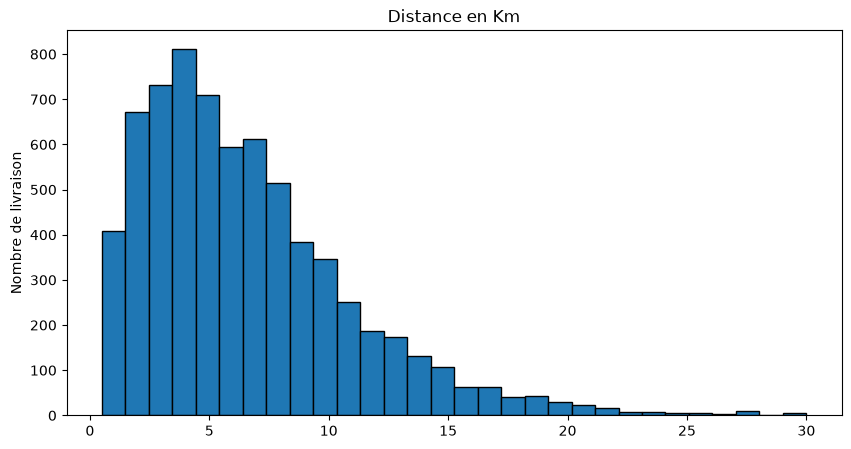

In [233]:
#Visualisation de la distance avec un histogramme
plt.figure(figsize=(10, 5))
plt.hist(df_num["distance_km"], bins=30, edgecolor="black")
plt.title("Distance en Km")
plt.ylabel("Nombre de livraison")
plt.show()

Text(0.5, 1.0, "Le nombres d'arrets")

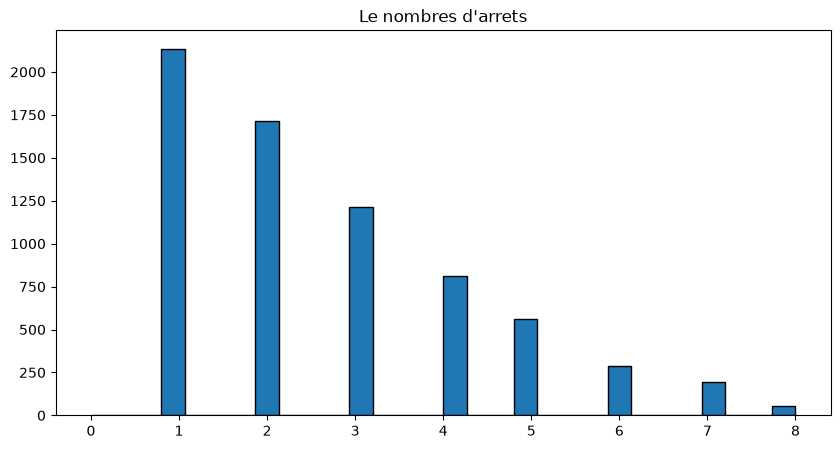

In [10]:
# Visualisation des nombres d'arrets avec histogramme
plt.figure(figsize=(10, 5))
plt.hist(df_num["nb_arrets"], bins = 30, edgecolor="black")
plt.title("Le nombres d'arrets")

Text(0.5, 1.0, 'Le poids en Kg')

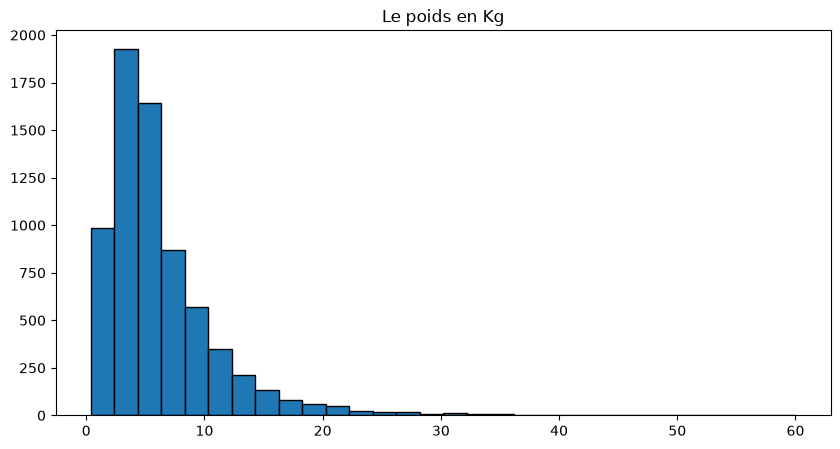

In [11]:
#Historique pour le poids avec un histogramme
plt.figure(figsize=(10, 5))
plt.hist(df_num["poids_kg"], bins=30, edgecolor="black")
plt.title("Le poids en Kg")

Text(0.5, 1.0, 'Heure de depart')

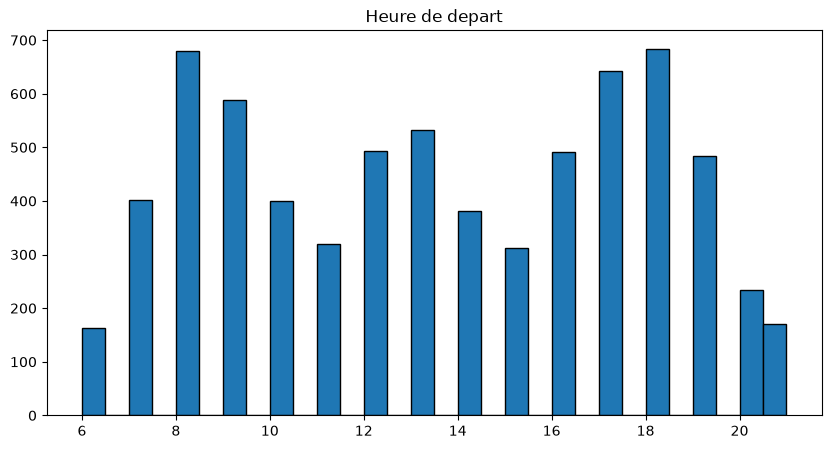

In [12]:
#Visualisation des heures de depart avec un histogramme
plt.figure(figsize=(10, 5))
plt.hist(df_num["heure_depart"], bins=30, edgecolor="black")
plt.title("Heure de depart")

Text(0.5, 1.0, "Trafic d'indice")

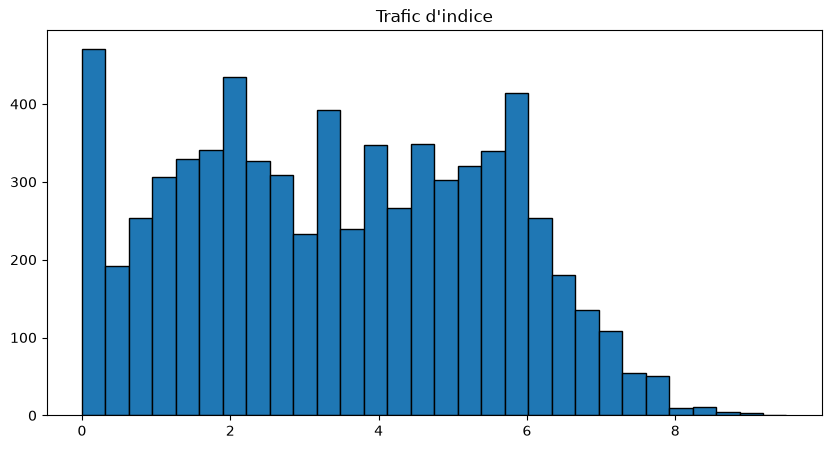

In [13]:
#Visualisation des indices du trafic de l'histogramme
plt.figure(figsize=(10, 5))
plt.hist(df_num["trafic_indice"], bins=30, edgecolor="black")
plt.title("Trafic d'indice")

Text(0, 0.5, 'valeurs')

<Figure size 1000x500 with 0 Axes>

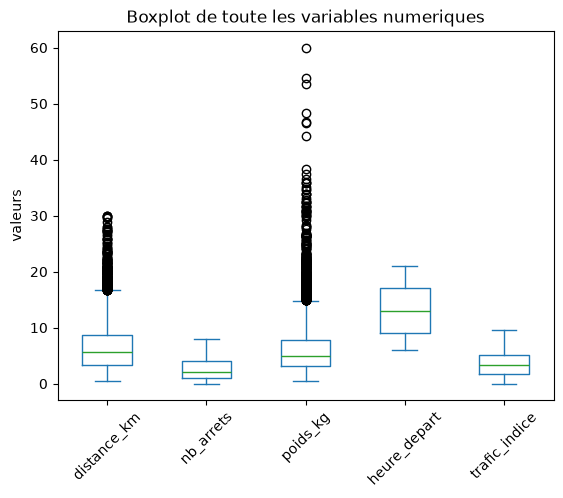

In [14]:
#Visualisation des features numerique avec boxplot
plt.figure(figsize=(10, 5))
df_num.plot(kind="box", rot=45)
plt.title("Boxplot de toute les variables numeriques")
plt.ylabel("valeurs")

In [15]:

# Remplacer 999.0 par nan dans la colonne distance_km malgré que cela a été fait en haut je le refais pour plus de brudence
df_num['distance_km'] = df_num['distance_km'].replace(999.0, np.nan)

valeur = (df_num["distance_km"] == 999.0).sum()
print(valeur)

df_num.loc[df_num["distance_km"] <= 0, "distance_km"] = np.nan
value_negative = (df_num["distance_km"] <= 0).sum()
print(value_negative)

X_train["distance_km"] = df_num["distance_km"]

0
0


J'ai choisi de changer la valeur outlier de la distance qui est 999.0 parce que je considere que c'est une erreur vu l'ecart qu'il a avec les d'autres nombres et dans beaucoup de ligne il apparait que sur 7 nombres

Text(0.5, 1.0, 'La durée des livraisons en min')

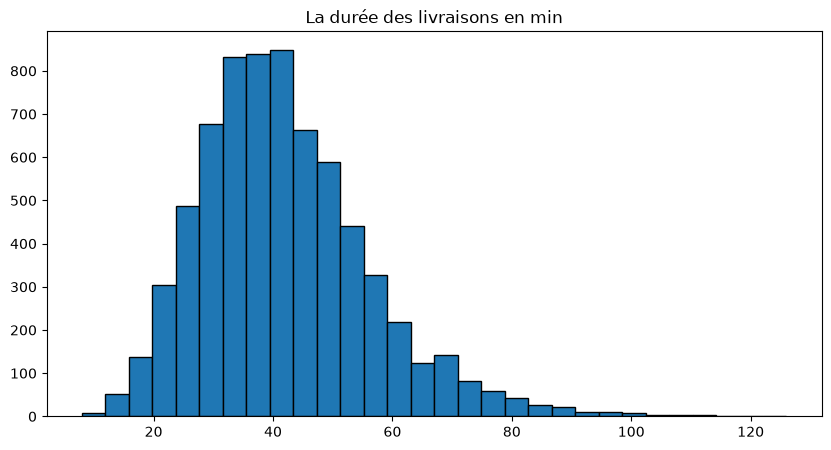

In [270]:
#Visualisation de notre variable cible avec un histogramme
plt.figure(figsize=(10, 5))
plt.hist(y_train, bins=30, edgecolor="black")
plt.title("La durée des livraisons en min")

In [16]:
voir = df_num[df_num["poids_kg"] >= 60]
print(voir)

      distance_km  nb_arrets  poids_kg  heure_depart  trafic_indice
5262          5.6          2      60.0            19            6.2


Index(['jour_semaine', 'meteo', 'type_vehicule'], dtype='str')


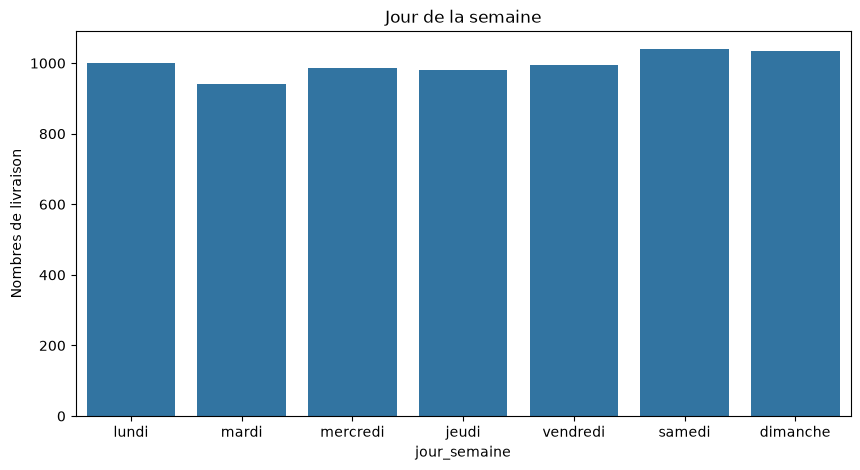

In [138]:
#Visualisation avec un diagramme en barre de des variables categoriques
print(df_str.columns)
ordre = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"] 
plt.figure(figsize=(10, 5))
sns.countplot(data=df_str, x="jour_semaine", order=ordre)
plt.title("Jour de la semaine")
plt.ylabel("Nombres de livraison")
plt.show()

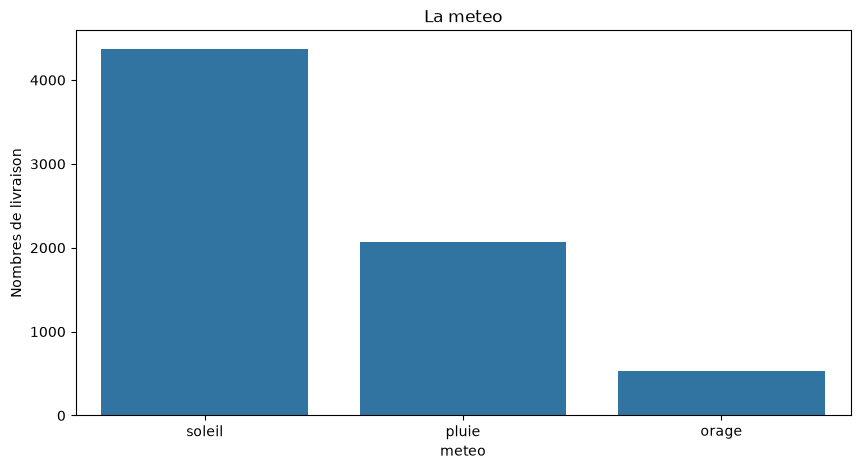

In [139]:

plt.figure(figsize=(10, 5))
sns.countplot(data = df_str,x="meteo")
plt.title("La meteo")
plt.ylabel("Nombres de livraison")
plt.show()

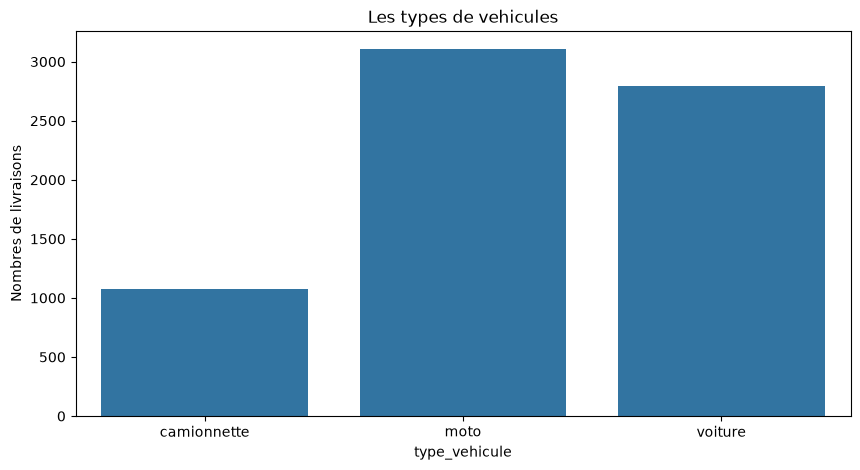

In [140]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_str, x="type_vehicule")
plt.title("Les types de vehicules")
plt.ylabel("Nombres de livraisons")
plt.show()

Text(0.5, 1.0, 'Relation entre la distance et le poids')

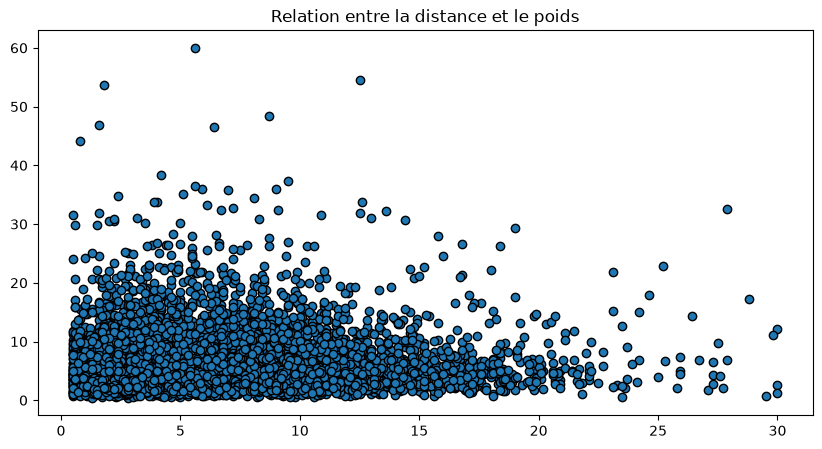

In [70]:
#Visualisation avec les nuages de points du rapport entre la distance et le poids
plt.figure(figsize=(10, 5))
plt.scatter(df_num["distance_km"], df_num["poids_kg"], edgecolor="black")
plt.title("Relation entre la distance et le poids")

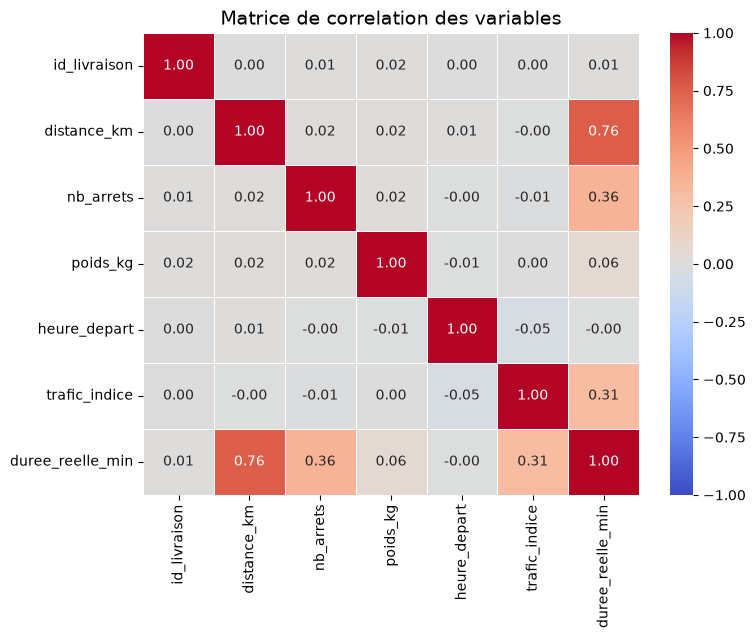

In [71]:
#Calculer la matrice de correlation
numerique = data_frame.select_dtypes(include=["int64", "float64"])
correlation_matrice= numerique.corr()
plt.figure(figsize=(8, 6))
# Afficher la matrice sous forme de Heatmap (carte de chaleur)
sns.heatmap(
    correlation_matrice, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Matrice de correlation des variables", fontsize=14)
plt.show()

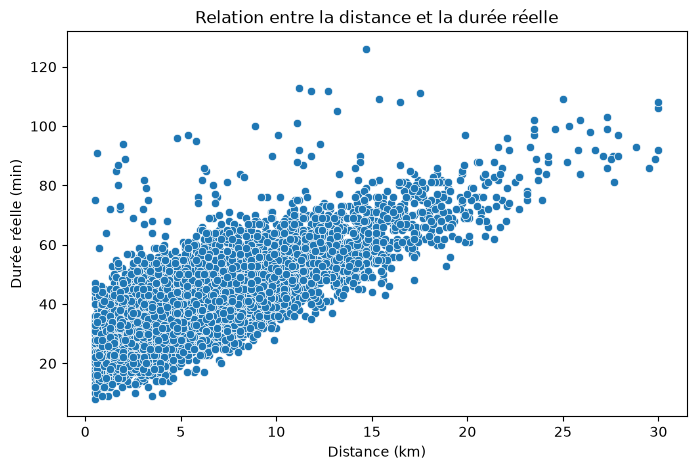

In [72]:
#Visualidation avec les nuages des points la relation entre la distance et la cible
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_train['distance_km'], y=y_train)
plt.title("Relation entre la distance et la durée réelle")
plt.xlabel("Distance (km)")
plt.ylabel("Durée réelle (min)")
plt.show()

In [249]:
#Suite a une durée de 0 dans notre cible sachant que la livraison a été lancé j'etais obligé de nettoyer
y_train = y_train.mask(y_train <= 0, np.nan)

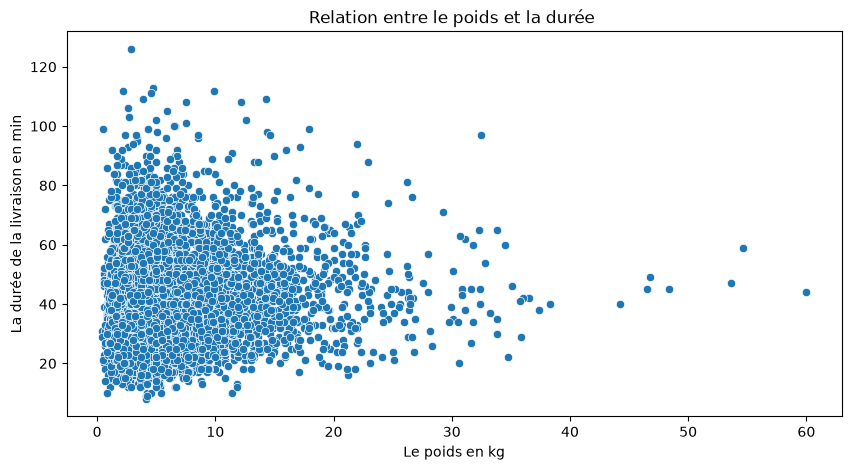

In [252]:
#Visualisation nuage des points la relation entre le poids et la cible
plt.figure(figsize=(10, 5))
sns.scatterplot(x=X_train["poids_kg"], y=y_train)
plt.title("Relation entre le poids et la durée ")
plt.xlabel("Le poids en kg")
plt.ylabel("La durée de la livraison en min")
plt.show()

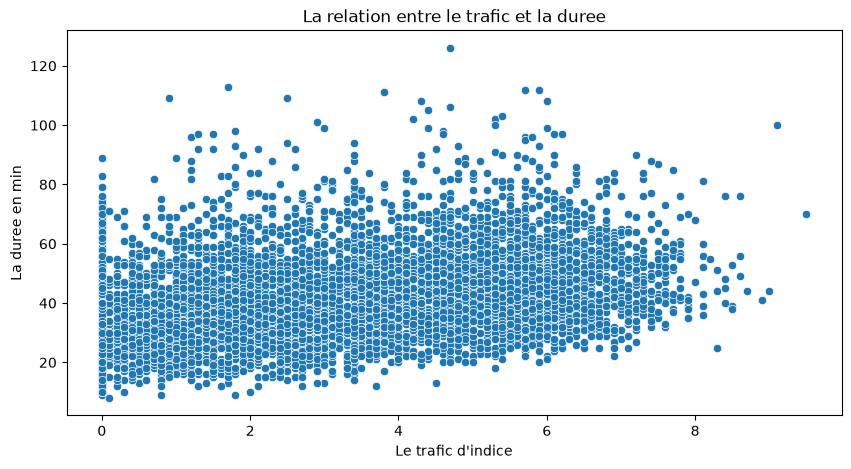

In [254]:
#Le trafic d'indice avec la cible
plt.figure(figsize=(10, 5))
sns.scatterplot(x=X_train["trafic_indice"], y=y_train)
plt.title("La relation entre le trafic et la duree")
plt.xlabel("Le trafic d'indice")
plt.ylabel("La duree en min")
plt.show()

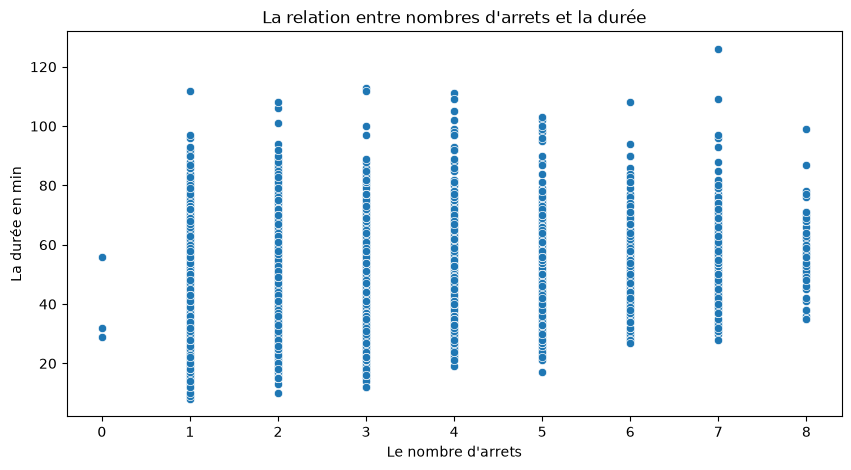

In [256]:
#Le nombre d'arrets avec la cible
plt.figure(figsize=(10, 5))
sns.scatterplot(x=X_train["nb_arrets"], y=y_train)
plt.title("La relation entre nombres d'arrets et la durée")
plt.xlabel("Le nombre d'arrets")
plt.ylabel("La durée en min")
plt.show()

Text(0, 0.5, 'valeurs')

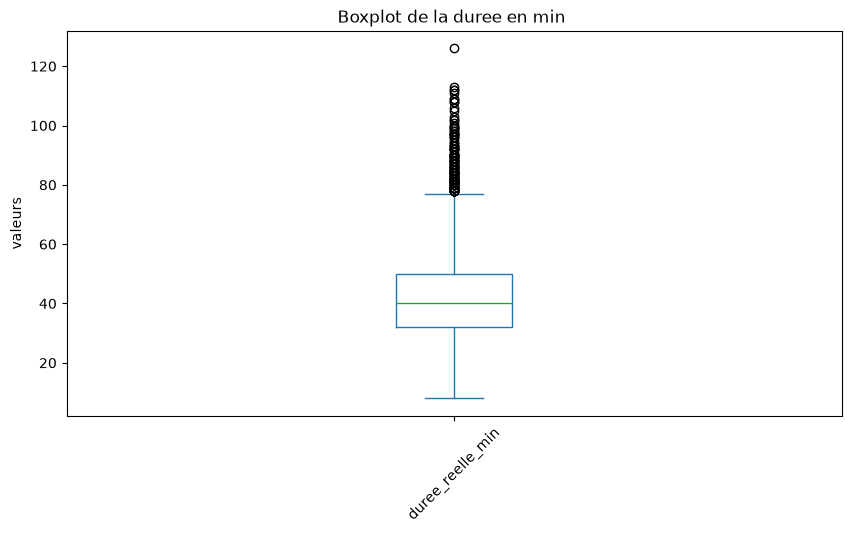

In [257]:
#Boxplot de la cible
plt.figure(figsize=(10, 5))
y_train.plot(kind="box", rot=45)
plt.title("Boxplot de la duree en min ")
plt.ylabel("valeurs")

In [141]:
print("TRAIN")
print(X_train['distance_km'].describe())
print("TEST")
print(X_test['distance_km'].describe())

TRAIN
count    6964.000000
mean        6.569213
std         4.398220
min         0.500000
25%         3.300000
50%         5.600000
75%         8.700000
max        30.000000
Name: distance_km, dtype: float64
TEST
count    1505.000000
mean        6.456412
std         4.342891
min         0.500000
25%         3.200000
50%         5.400000
75%         8.700000
max        30.000000
Name: distance_km, dtype: float64


In [265]:
#Nettoyage dans les donnees test et validation
X_test["distance_km"]=X_test["distance_km"].replace(999.0, np.nan)
X_test.loc[X_test["distance_km"] <= 0, "distance_km"] = np.nan

In [7]:
X_validation["distance_km"]=X_validation["distance_km"].replace(999.0, np.nan)
X_validation.loc[X_validation["distance_km"] <= 0, "distance_km"] = np.nan
print("VALIDATION")
print(X_validation["distance_km"].describe())

VALIDATION
count    1486.000000
mean        6.670929
std         4.594150
min         0.500000
25%         3.300000
50%         5.600000
75%         8.700000
max        30.000000
Name: distance_km, dtype: float64


In [8]:
print(X_validation["poids_kg"])

6990    12.1
6991     9.0
6998     6.6
6997     5.6
6994     5.3
        ... 
8464     5.2
8463     2.0
8461     4.1
8460     7.2
8462     3.7
Name: poids_kg, Length: 1491, dtype: float64


In [9]:
y_test = y_test.mask(y_test <= 0, np.nan)

In [11]:
y_validation = y_validation.mask(y_validation <= 0, np.nan)

In [52]:
# Affiche le nombre de NaN par colonne
print(df_num["distance_km"].isna().sum())

12


In [271]:
# Supprime toutes les lignes qui contiennent au moins un NaN dans les colonnes clés
data_frame = data_frame.dropna(subset=['distance_km', 'duree_reelle_min'])
print(data_frame.isna().sum())

id_livraison        0
date_commande       0
distance_km         0
nb_arrets           0
poids_kg            0
heure_depart        0
jour_semaine        0
meteo               0
type_vehicule       0
trafic_indice       0
duree_reelle_min    0
dtype: int64


In [75]:
print(data_frame.duplicated().sum())

0


In [76]:
print(data_frame.columns)

Index(['id_livraison', 'date_commande', 'distance_km', 'nb_arrets', 'poids_kg',
       'heure_depart', 'jour_semaine', 'meteo', 'type_vehicule',
       'trafic_indice', 'duree_reelle_min'],
      dtype='str')


In [82]:
print(len(df_num))

6976


In [80]:
print(len(X_validation))

1491


In [84]:
print(len(X_test))

1508


In [86]:
print(df_str.columns)

Index(['jour_semaine', 'meteo', 'type_vehicule'], dtype='str')


In [22]:
print(df_str.value_counts(dropna=False))

jour_semaine  meteo   type_vehicule
dimanche      soleil  moto             309
lundi         soleil  moto             308
samedi        soleil  moto             291
jeudi         soleil  voiture          270
vendredi      soleil  moto             268
                                      ... 
jeudi         orage   camionnette       15
vendredi      orage   camionnette       10
mardi         orage   camionnette       10
dimanche      orage   camionnette        9
lundi         orage   camionnette        8
Name: count, Length: 63, dtype: int64


In [27]:

# Initialisation de l'encodeur
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

#Fit et transform sur le train des catégories
train_str_encoded_array = encoder.fit_transform(df_str)

#Récupérer les nouveaux noms de colonnes
noms_colonnes = encoder.get_feature_names_out(df_str.columns)

#Transformer en DataFrame propre
df_str_train_encoded = pd.DataFrame(
    train_str_encoded_array, 
    columns=noms_colonnes, 
    index=df_str.index
)

In [29]:
#Concaténation horizontale (axis=1) des numériques et des catégories encodées
X_train_final = pd.concat([df_num, df_str_train_encoded], axis=1)

print("Dimensions de X_train_final :", X_train_final.shape)

Dimensions de X_train_final : (6976, 18)


In [273]:

#Nettoyage des cibles
# On retire uniquement les observations dont la cible est manquante ou invalide.
masque_train = y_train.notna() & (y_train > 0)
masque_validation = y_validation.notna() & (y_validation > 0)
masque_test = y_test.notna() & (y_test > 0)

y_train = y_train.loc[masque_train]
y_validation = y_validation.loc[masque_validation]
y_test = y_test.loc[masque_test]

# On conserve les mêmes lignes dans les variables X.
X_train_final = X_train_final.loc[masque_train]

# Endage de validation et test
# On utilise l'encodeur déjà appris sur le train.
validation_encoded = encoder.transform(
    X_validation[df_str.columns]
)

test_encoded = encoder.transform(
    X_test[df_str.columns]
)

# Conversion en DataFrames avec les mêmes colonnes.
df_str_validation = pd.DataFrame(
    validation_encoded,
    columns=noms_colonnes,
    index=X_validation.index
)

df_str_test = pd.DataFrame(
    test_encoded,
    columns=noms_colonnes,
    index=X_test.index
)


#Preparer les variables numeriques
# On récupère les mêmes colonnes numériques
# dans les trois ensembles.
num_train = df_num.loc[masque_train].copy()

num_validation = X_validation.loc[
    masque_validation, df_num.columns
].copy()

num_test = X_test.loc[
    masque_test, df_num.columns
].copy()

# Imputation par médiane.
# La médiane est apprise uniquement sur le train.
imputer = SimpleImputer(strategy="median")

num_train_imputed = imputer.fit_transform(num_train)

num_validation_imputed = imputer.transform(num_validation)

num_test_imputed = imputer.transform(num_test)


#STANDARDISER LES VARIABLES NUMÉRIQUES
# La standardisation est apprise uniquement sur le train.
scaler = StandardScaler()

num_train_scaled = scaler.fit_transform(num_train_imputed)

num_validation_scaled = scaler.transform(num_validation_imputed)

num_test_scaled = scaler.transform(num_test_imputed)


#RECONSTRUIRE LES ENSEMBLES FINAUX

num_train_final = pd.DataFrame(
    num_train_scaled,
    columns=df_num.columns,
    index=num_train.index
)

num_validation_final = pd.DataFrame(
    num_validation_scaled,
    columns=df_num.columns,
    index=num_validation.index
)

num_test_final = pd.DataFrame(
    num_test_scaled,
    columns=df_num.columns,
    index=num_test.index
)

X_train_final = pd.concat(
    [num_train_final, df_str_train_encoded.loc[masque_train]],
    axis=1
)

X_validation_final = pd.concat(
    [num_validation_final, df_str_validation.loc[masque_validation]],
    axis=1
)

X_test_final = pd.concat(
    [num_test_final, df_str_test.loc[masque_test]],
    axis=1
)



# 6. VÉRIFICATIONS FINALES
print("TRAIN :", X_train_final.shape, y_train.shape)
print("VALIDATION :", X_validation_final.shape, y_validation.shape)
print("TEST :", X_test_final.shape, y_test.shape)

print("\nValeurs manquantes :")
print("Train :", X_train_final.isna().sum().sum())
print("Validation :", X_validation_final.isna().sum().sum())
print("Test :", X_test_final.isna().sum().sum())

print("\nColonnes identiques :")
print(
    list(X_train_final.columns)
    == list(X_validation_final.columns)
    == list(X_test_final.columns)
)

# Vérification de l'alignement entre X et y.
assert X_train_final.index.equals(y_train.index)
assert X_validation_final.index.equals(y_validation.index)
assert X_test_final.index.equals(y_test.index)

assert X_train_final.shape[1] == X_validation_final.shape[1]
assert X_train_final.shape[1] == X_test_final.shape[1]

print("Préparation finale vérifiée.")


TRAIN : (6969, 18) (6969,)
VALIDATION : (1490, 18) (1490,)
TEST : (1506, 18) (1506,)

Valeurs manquantes :
Train : 0
Validation : 0
Test : 0

Colonnes identiques :
True

Préparation finale vérifiée.


In [31]:
# BASELINE : PRÉDICTION PAR LA MOYENNE
# Calcul de la durée moyenne sur les données d'entraînement.
duree_moyenne = y_train.mean()

# Prédictions constantes sur train et validation.
baseline_train = np.full(
    shape=len(y_train),
    fill_value=duree_moyenne
)

baseline_validation = np.full(
    shape=len(y_validation),
    fill_value=duree_moyenne
)

print("Durée moyenne du train :", duree_moyenne)
print("Nombre de prédictions train :", len(baseline_train))
print("Nombre de prédictions validation :", len(baseline_validation))


Durée moyenne du train : 41.912613000430476
Nombre de prédictions train : 6969
Nombre de prédictions validation : 1490


In [280]:
#calcul metrique

m_baseline = len(baseline_train)

mae_baseline_train = sum(abs(y_train - baseline_train)) / m_baseline

erreur_baseline_individuel = y_train - baseline_train
erreur_carre_baseline_individuel = erreur_baseline_individuel ** 2

rmse_baseline_train = np.sqrt(sum(erreur_carre_baseline_individuel) / m_baseline)


#r2_baseline_train
erreur_commis = np.sum((y_train - baseline_train) ** 2)
erreur_naif = np.sum((y_train - np.mean(y_train)) ** 2)

#Calcul de la R2
r2_baseline_train = 1 - (erreur_commis / erreur_naif)


# Évaluation de la baseline sur la validation.
m_baseline_vali = len(baseline_validation)

mae_baseline_validation = sum(abs(y_validation - baseline_validation)) / m_baseline_vali

erreur_baseline_vali = y_validation - baseline_validation

erreur_baseline_vali_carre = erreur_baseline_vali ** 2

rmse_baseline_validation = np.sqrt(sum(erreur_baseline_vali_carre) / m_baseline_vali)


erreur_commis_vali = np.sum((y_validation - baseline_validation) ** 2)
erreur_naif_vali = np.sum((y_validation - np.mean(y_validation)) ** 2)

#Calcul de la R2
r2_baseline_validation = 1 - (erreur_commis_vali / erreur_naif_vali)


#Affichage des résultats.
print("BASELINE TRAIN")
print("MAE :", mae_baseline_train)
print("RMSE :", rmse_baseline_train)
print("R² :", r2_baseline_train)

print("BASELINE VALIDATION")
print("MAE :", mae_baseline_validation)
print("RMSE :", rmse_baseline_validation)
print("R² :", r2_baseline_validation)


BASELINE TRAIN
MAE : 11.122108752079424
RMSE : 14.408218293258061
R² : 0.0
BASELINE VALIDATION
MAE : 11.132122891308683
RMSE : 14.626062318891373
R² : -0.00010870808134821885


In [62]:
X = np.array(X_train_final)
W = np.zeros(X.shape[1])
b = 0.0
y_barre = X @ W + b
print(y_barre)

# Calcul de la fontion de cout
y_erreur = np.array(y_train)
y_barre_erreur = np.array(y_barre)

erreur_individuel = y_barre_erreur - y_erreur

print(erreur_individuel)

erreur_carre = erreur_individuel ** 2
print(erreur_carre)

m = len(X_train_final)
print(m)

fonction_cout = sum(erreur_carre) / (2 * m)
print("La fonction cout  : ",fonction_cout)

[0. 0. 0. ... 0. 0. 0.]
[-53. -54. -80. ... -33. -36. -61.]
[2809. 2916. 6400. ... 1089. 1296. 3721.]
6969
La fonction cout  :  982.1319414550151


In [65]:
#Calcul le gradient du biais

db = sum(erreur_individuel) / m
print(db)

-41.912613000430476


In [73]:
#Calcul le gradient des poids
#print(X_train_final.shape)
X_train_final_transposé = X_train_final.T
dW = X_train_final_transposé @ erreur_individuel / m
print(dW)
print(dW.shape)

distance_km                 -10.917454
nb_arrets                    -5.163778
poids_kg                     -0.660426
heure_depart                  0.099703
trafic_indice                -4.592453
jour_semaine_dimanche        -5.840723
jour_semaine_jeudi           -5.925814
jour_semaine_lundi           -6.117377
jour_semaine_mardi           -5.799684
jour_semaine_mercredi        -6.157698
jour_semaine_samedi          -5.974171
jour_semaine_vendredi        -6.097144
meteo_orage                  -3.769838
meteo_pluie                 -12.802267
meteo_soleil                -25.340508
type_vehicule_camionnette    -7.129717
type_vehicule_moto          -17.841154
type_vehicule_voiture       -16.941742
dtype: float64
(18,)


In [79]:
#La mise a jour des parametres W et b pour minimiser la fonction de cout
#Mise a jour du biais b
alpha = 0.1
b_nouveau = b - (alpha * db)
print(b_nouveau)

4.191261300043048


In [81]:
#Mise a jour du poids W
W_nouveau = W - (alpha * dW)
print(W_nouveau)

distance_km                  1.091745
nb_arrets                    0.516378
poids_kg                     0.066043
heure_depart                -0.009970
trafic_indice                0.459245
jour_semaine_dimanche        0.584072
jour_semaine_jeudi           0.592581
jour_semaine_lundi           0.611738
jour_semaine_mardi           0.579968
jour_semaine_mercredi        0.615770
jour_semaine_samedi          0.597417
jour_semaine_vendredi        0.609714
meteo_orage                  0.376984
meteo_pluie                  1.280227
meteo_soleil                 2.534051
type_vehicule_camionnette    0.712972
type_vehicule_moto           1.784115
type_vehicule_voiture        1.694174
dtype: float64


In [92]:
# Calcul de la prediction
y_barre_nouveau = X @ W_nouveau + b_nouveau
print(y_barre_nouveau)

#Calcul de l'erreur
erreur_individuel_nouveau = y_barre_nouveau - y_erreur
print("erreur_individuel est :", erreur_individuel_nouveau)

# Calcul de la fonction de cout
erreur_individuel_nouveau_carre = erreur_individuel_nouveau ** 2

fonction_cout_nouveau = sum(erreur_individuel_nouveau_carre) / (2 * m)
print("La fonction de cout est : ",fonction_cout_nouveau)


[ 8.62091245  8.75303645 11.39955349 ...  8.99204723  7.42179881
 10.88669396]
erreur_individuel est : [-44.37908755 -45.24696355 -68.60044651 ... -24.00795277 -28.57820119
 -50.11330604]
La fonction de cout est :  653.2306256163392


In [122]:
X_iter = np.array(X_train_final)
W_iter = np.zeros(X_iter.shape[1])
iteractions = 1000
alpha = 0.1
b_iter = 0.0
historique_cout = []
epsilon = 1e-8
cout_precedent = None

X_train_final_T = X_train_final.T

for i in range(iteractions):
    y_iter_prediction = X_iter @ W_iter + b_iter

    erreur_iter = y_iter_prediction - y_erreur
    erreur_iter_carre = erreur_iter ** 2
    fonction_cout_iter = sum(erreur_iter_carre) / ( 2 * m)

    # Vérification de la convergence
    if cout_precedent is not None:
        variation_cout = abs(cout_precedent - fonction_cout_iter)

        if variation_cout < epsilon:
            print(f"Convergence atteinte à l'itération {i + 1}")
            break

    # Mise à jour du coût précédent
    cout_precedent = fonction_cout_iter
    
    historique_cout.append(fonction_cout_iter)

    db_iter = sum(erreur_iter) / m
    dW_iter = X_train_final_T @ erreur_iter / m

    b_iter_nouveau = b_iter - (alpha * db_iter)
    b_iter = b_iter_nouveau
    W_iter_nouveau = W_iter - (alpha * dW_iter)
    W_iter = W_iter_nouveau

    #Arret de la boucle lorsque le modele ne progresse plus
    
print(f"Les 5 premiers : ", historique_cout[:5])
print(f"Les 5 derniers : ", historique_cout[-5:])

Convergence atteinte à l'itération 854
Les 5 premiers :  [np.float64(982.1319414550151), np.float64(653.2306256163392), np.float64(441.5983232277025), np.float64(304.8174016668586), np.float64(215.9085027872898)]
Les 5 derniers :  [np.float64(14.265991452476054), np.float64(14.265991441717512), np.float64(14.265991431169889), np.float64(14.26599142082926), np.float64(14.265991410691393)]


In [123]:
#Mesure de la convergence
J_1000 = historique_cout[-1]
J_999 = historique_cout[-2]

Delta_J = abs(J_1000 - J_999)
print(Delta_J)

1.0137867434423242e-08


In [125]:
print(f"Le dernier nombre : ", historique_cout[-1])
print(f"Le nombre de nombre : ", len(historique_cout))

Le dernier nombre :  14.265991410691393
Le nombre de nombre :  853


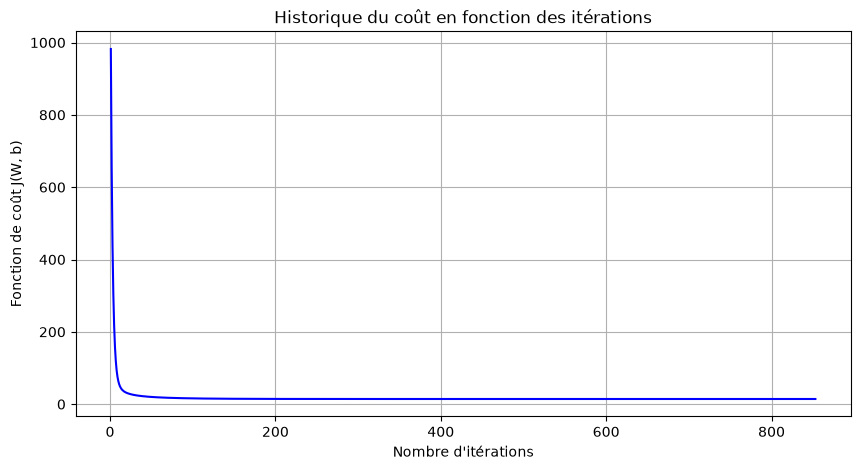

In [132]:
iterations = range(1, len(historique_cout) + 1)

plt.figure(figsize=(10, 5))

plt.plot(iterations, historique_cout, color="blue")

plt.title("Historique du coût en fonction des itérations")
plt.xlabel("Nombre d'itérations")
plt.ylabel("Fonction de coût J(W, b)")

plt.grid(True)
plt.show()

In [142]:
print("X_train_final :", X_train_final.shape)
print("X_validation :", X_validation_final.shape)
print("W_iter :", W_iter.shape)

print("Colonnes train :", list(X_train_final.columns))
print("Colonnes validation :", list(X_validation.columns))

X_train_final : (6969, 18)
X_validation : (1490, 18)
W_iter : (18,)
Colonnes train : ['distance_km', 'nb_arrets', 'poids_kg', 'heure_depart', 'trafic_indice', 'jour_semaine_dimanche', 'jour_semaine_jeudi', 'jour_semaine_lundi', 'jour_semaine_mardi', 'jour_semaine_mercredi', 'jour_semaine_samedi', 'jour_semaine_vendredi', 'meteo_orage', 'meteo_pluie', 'meteo_soleil', 'type_vehicule_camionnette', 'type_vehicule_moto', 'type_vehicule_voiture']
Colonnes validation : ['date_commande', 'distance_km', 'nb_arrets', 'poids_kg', 'heure_depart', 'jour_semaine', 'meteo', 'type_vehicule', 'trafic_indice']


In [143]:
y_barre_val = X_validation_final @ W_iter + b_iter
print(y_barre_val)

6990    21.911417
6991    37.525756
6998    71.147239
6997    27.557903
6994    33.440773
          ...    
8464    30.317826
8463    32.047056
8461    48.266690
8460    49.636780
8462    33.399511
Length: 1490, dtype: float64


In [156]:
print(y_validation.shape)
print(y_barre_val.shape)
print(len(y_validation))
m_val = len(y_validation)
erreur_validation = y_barre_val - y_validation
erreur_validation_carre = erreur_validation ** 2
mae = sum(abs(erreur_validation)) / m_val

rmse = np.sqrt(sum(erreur_validation_carre) / m_val)
print(mae)
print(rmse)


(1490,)
(1490,)
1490
3.1095551791909073
4.825203909875035


In [158]:
moyenne_y_validation = np.mean(y_validation)
erreur_moyenne = y_validation - moyenne_y_validation
erreur_moyenne_carre = erreur_moyenne ** 2
r_carre = 1 - (sum(erreur_validation_carre) / sum(erreur_moyenne_carre))
print(r_carre)

0.891151183393315


In [160]:
amelioration = mae_baseline_validation / mae
print(amelioration)

3.579972777394229


In [161]:
calcul_mae =11.1321 / 3.1096
print(calcul_mae)

3.5799138152817083


In [163]:
print(np.max(erreur_validation))
print(np.abs(erreur_validation))

14.157440185623514
6990     1.088583
6991     4.525756
6998    30.852761
6997     2.442097
6994     1.559227
          ...    
8464     4.317826
8463     2.952944
8461     1.266690
8460     0.636780
8462     0.399511
Length: 1490, dtype: float64


In [166]:
print(np.argmax(erreur_validation))
print(np.max(erreur_validation))

117
14.157440185623514


In [167]:
print("Durée réelle :", y_validation.iloc[117])
print("Durée prédite :", y_barre_val.iloc[117])
print("Erreur absolue :", abs(erreur_validation.iloc[117]))

Durée réelle : 40.0
Durée prédite : 54.157440185623514
Erreur absolue : 14.157440185623514


In [169]:
print(X_validation_final.iloc[117])

distance_km                  0.576038
nb_arrets                    0.777314
poids_kg                     0.895974
heure_depart                -1.266904
trafic_indice                0.457959
jour_semaine_dimanche        1.000000
jour_semaine_jeudi           0.000000
jour_semaine_lundi           0.000000
jour_semaine_mardi           0.000000
jour_semaine_mercredi        0.000000
jour_semaine_samedi          0.000000
jour_semaine_vendredi        0.000000
meteo_orage                  0.000000
meteo_pluie                  1.000000
meteo_soleil                 0.000000
type_vehicule_camionnette    0.000000
type_vehicule_moto           1.000000
type_vehicule_voiture        0.000000
Name: 7091, dtype: float64


In [171]:
print(X_validation.iloc[117])

date_commande    2026-01-25 00:00:00
distance_km                      9.1
nb_arrets                          4
poids_kg                        10.6
heure_depart                       8
jour_semaine                dimanche
meteo                          pluie
type_vehicule                   moto
trafic_indice                    4.4
Name: 7091, dtype: object


In [172]:
print(W_iter)

distance_km                  10.937681
nb_arrets                     5.093354
poids_kg                      0.599790
heure_depart                  0.058681
trafic_indice                 4.569412
jour_semaine_dimanche         2.891566
jour_semaine_jeudi            4.105668
jour_semaine_lundi            3.780600
jour_semaine_mardi            3.509834
jour_semaine_mercredi         3.868779
jour_semaine_samedi           3.234970
jour_semaine_vendredi         3.830453
meteo_orage                  14.090246
meteo_pluie                   7.442435
meteo_soleil                  3.689189
type_vehicule_camionnette    11.625611
type_vehicule_moto            5.786254
type_vehicule_voiture         7.810005
dtype: float64


In [173]:
print(b_iter)

25.221869512101687


In [175]:
print(X_validation_final.iloc[117] @ W_iter)

28.935570673521823


In [176]:
contributions = X_validation_final.iloc[117] * W_iter

print(contributions)

distance_km                  6.300525
nb_arrets                    3.959133
poids_kg                     0.537396
heure_depart                -0.074343
trafic_indice                2.092606
jour_semaine_dimanche        2.891566
jour_semaine_jeudi           0.000000
jour_semaine_lundi           0.000000
jour_semaine_mardi           0.000000
jour_semaine_mercredi        0.000000
jour_semaine_samedi          0.000000
jour_semaine_vendredi        0.000000
meteo_orage                  0.000000
meteo_pluie                  7.442435
meteo_soleil                 0.000000
type_vehicule_camionnette    0.000000
type_vehicule_moto           5.786254
type_vehicule_voiture        0.000000
dtype: float64


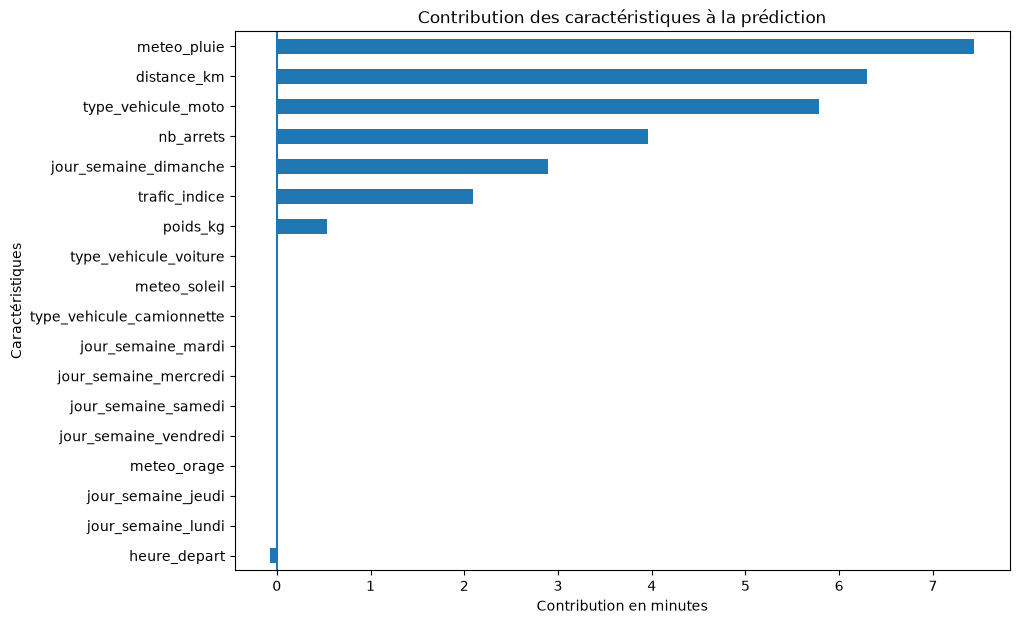

In [177]:
contributions.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Contribution des caractéristiques à la prédiction"
)

plt.xlabel("Contribution en minutes")
plt.ylabel("Caractéristiques")
plt.axvline(0)
plt.show()

In [178]:
erreurs_absolues = erreur_validation.abs()

top_10_erreurs = erreurs_absolues.sort_values(
    ascending=False
).head(10)

print(top_10_erreurs)

7940    55.987839
7015    53.486853
7705    45.330867
7848    40.972789
7616    38.384806
8062    37.689793
7179    34.930718
6998    30.852761
7091    14.157440
7028    13.550779
dtype: float64


In [179]:
analyse_erreurs = pd.DataFrame({
    "duree_reelle": y_validation.loc[top_10_erreurs.index],
    "duree_predite": y_barre_val.loc[top_10_erreurs.index],
    "erreur": erreur_validation.loc[top_10_erreurs.index],
    "erreur_absolue": top_10_erreurs
})

print(analyse_erreurs)

      duree_reelle  duree_predite     erreur  erreur_absolue
7940          98.0      42.012161 -55.987839       55.987839
7015          95.0      41.513147 -53.486853       53.486853
7705          88.0      42.669133 -45.330867       45.330867
7848         100.0      59.027211 -40.972789       40.972789
7616          72.0      33.615194 -38.384806       38.384806
8062          92.0      54.310207 -37.689793       37.689793
7179          64.0      29.069282 -34.930718       34.930718
6998         102.0      71.147239 -30.852761       30.852761
7091          40.0      54.157440  14.157440       14.157440
7028          77.0      63.449221 -13.550779       13.550779


In [180]:
indices = top_10_erreurs.index[:8]

print(X_validation.loc[indices])

     date_commande  distance_km  nb_arrets  poids_kg  heure_depart  \
7940    2026-03-12          4.0          5       2.4            16   
7015    2026-01-21          5.2          1       7.3             8   
7705    2026-02-28          9.2          1       6.5            17   
7848    2026-03-07         10.1          3       1.5            17   
7616    2026-02-23          5.8          1       2.2             7   
8062    2026-03-19          8.3          3       4.3            12   
7179    2026-01-29          2.0          4       4.1            16   
6998    2026-01-20         10.7          7       6.6             8   

     jour_semaine   meteo type_vehicule  trafic_indice  
7940        jeudi  soleil   camionnette            2.2  
7015     mercredi   pluie       voiture            6.0  
7705       samedi  soleil       voiture            4.0  
7848       samedi   pluie   camionnette            4.5  
7616        lundi  soleil          moto            4.7  
8062        jeudi   orage  

In [181]:
print(y_train.describe())

count    6969.000000
mean       41.912613
std        14.409252
min         8.000000
25%        32.000000
50%        40.000000
75%        50.000000
max       126.000000
Name: duree_reelle_min, dtype: float64


In [182]:
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)

IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)

Q1 : 32.0
Q3 : 50.0
IQR : 18.0
Borne inférieure : 5.0
Borne supérieure : 77.0


In [183]:
valeurs_atypiques = y_train[y_train > borne_sup]

print("Nombre de valeurs atypiques :", len(valeurs_atypiques))
print("Pourcentage :", len(valeurs_atypiques) / len(y_train) * 100)

Nombre de valeurs atypiques : 142
Pourcentage : 2.0375950638542117


In [184]:
indices_atypiques = valeurs_atypiques.index

print(X_train.loc[indices_atypiques].describe())

                    date_commande  distance_km   nb_arrets    poids_kg  \
count                         142   141.000000  142.000000  142.000000   
mean   2025-07-24 03:02:32.112676    17.873759    3.661972    6.574648   
min           2025-01-01 00:00:00     0.600000    1.000000    0.500000   
25%           2025-04-18 18:00:00    14.400000    2.000000    3.225000   
50%           2025-07-31 00:00:00    18.400000    4.000000    5.000000   
75%           2025-10-24 12:00:00    23.100000    5.000000    7.500000   
max           2026-01-18 00:00:00    30.000000    8.000000   32.500000   
std                           NaN     7.094119    1.996050    5.181602   

       heure_depart  trafic_indice  
count    142.000000     142.000000  
mean      14.014085       4.299296  
min        6.000000       0.000000  
25%        9.000000       3.000000  
50%       16.000000       4.700000  
75%       18.000000       5.700000  
max       21.000000       9.100000  
std        4.411439       1.942562  


In [185]:
print(X_train.describe())

                    date_commande  distance_km    nb_arrets     poids_kg  \
count                        6976  6964.000000  6976.000000  6976.000000   
mean   2025-07-13 06:55:31.651376     6.569213     2.691800     6.235292   
min           2025-01-01 00:00:00     0.500000     0.000000     0.400000   
25%           2025-04-09 00:00:00     3.300000     1.000000     3.100000   
50%           2025-07-13 00:00:00     5.600000     2.000000     5.000000   
75%           2025-10-18 00:00:00     8.700000     4.000000     7.800000   
max           2026-01-19 00:00:00    30.000000     8.000000    60.000000   
std                           NaN     4.398220     1.682095     4.871418   

       heure_depart  trafic_indice  
count   6976.000000    6976.000000  
mean      13.392202       3.456723  
min        6.000000       0.000000  
25%        9.000000       1.700000  
50%       13.000000       3.400000  
75%       17.000000       5.200000  
max       21.000000       9.500000  
std        4.255714

In [186]:
mask_longues = y_validation > 77

print("Nombre de livraisons longues :", mask_longues.sum())

print(
    "MAE sur les livraisons longues :",
    np.mean(np.abs(y_barre_val[mask_longues] - y_validation[mask_longues]))
)

print(
    "Erreur moyenne signée :",
    np.mean(y_barre_val[mask_longues] - y_validation[mask_longues])
)

Nombre de livraisons longues : 37
MAE sur les livraisons longues : 9.56871812646462
Erreur moyenne signée : -8.500825295240217


In [187]:
mask_longues = y_validation > 77
mask_normales = ~mask_longues

mae_normales = np.mean(
    np.abs(y_barre_val[mask_normales] - y_validation[mask_normales])
)

mae_longues = np.mean(
    np.abs(y_barre_val[mask_longues] - y_validation[mask_longues])
)

print("MAE livraisons normales :", mae_normales)
print("MAE livraisons longues :", mae_longues)

MAE livraisons normales : 2.9450754620201387
MAE livraisons longues : 9.56871812646462


In [188]:
erreur_normales = (
    y_barre_val[mask_normales] - y_validation[mask_normales]
)

print("Erreur moyenne normale :", np.mean(erreur_normales))

Erreur moyenne normale : 0.274506581216208


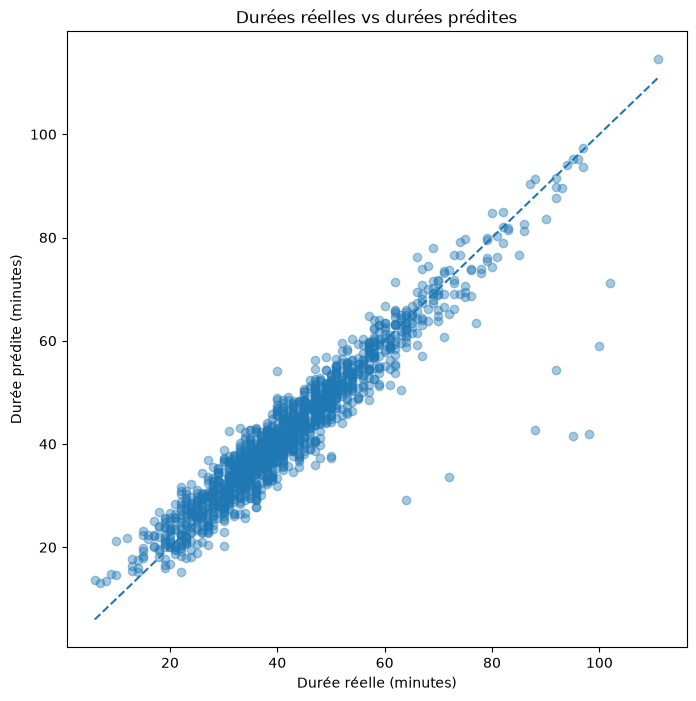

In [189]:
plt.figure(figsize=(8, 8))

plt.scatter(y_validation, y_barre_val, alpha=0.4)

plt.plot(
    [y_validation.min(), y_validation.max()],
    [y_validation.min(), y_validation.max()],
    linestyle="--"
)

plt.xlabel("Durée réelle (minutes)")
plt.ylabel("Durée prédite (minutes)")
plt.title("Durées réelles vs durées prédites")

plt.show()

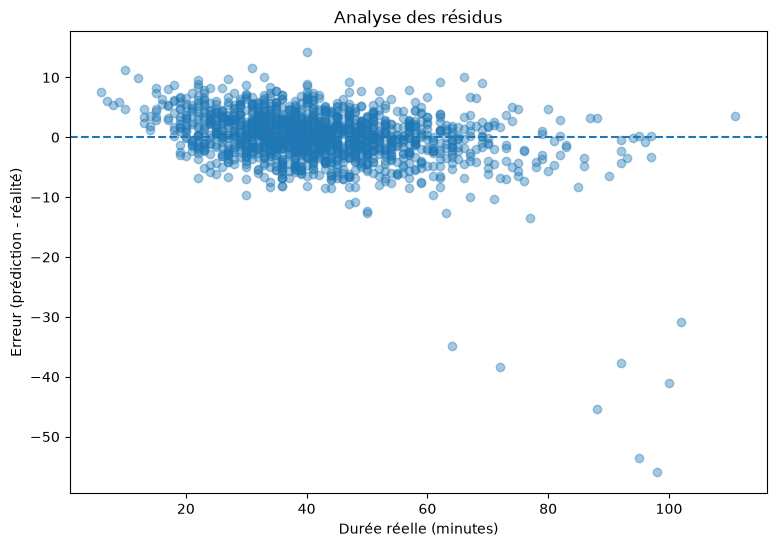

In [190]:
plt.figure(figsize=(9, 6))

plt.scatter(y_validation, erreur_validation, alpha=0.4)

plt.axhline(0, linestyle="--")

plt.xlabel("Durée réelle (minutes)")
plt.ylabel("Erreur (prédiction - réalité)")
plt.title("Analyse des résidus")

plt.show()

In [191]:
analyse_residus = pd.DataFrame({
    "duree_reelle": y_validation,
    "erreur": erreur_validation
})

analyse_residus["tranche"] = pd.cut(
    analyse_residus["duree_reelle"],
    bins=[0, 20, 40, 60, 80, 100, 130]
)

resultat = analyse_residus.groupby(
    "tranche",
    observed=False
).agg(
    nombre=("erreur", "count"),
    erreur_moyenne=("erreur", "mean"),
    erreur_absolue_moyenne=("erreur", lambda x: x.abs().mean())
)

print(resultat)

            nombre  erreur_moyenne  erreur_absolue_moyenne
tranche                                                   
(0, 20]         61        3.801415                4.128366
(20, 40]       698        0.821380                2.884160
(40, 60]       577       -0.321606                2.710468
(60, 80]       125       -1.885355                3.821233
(80, 100]       27      -10.084367               10.827093
(100, 130]       2      -13.684053               17.168708


In [192]:
correlation_distance = X_train["distance_km"].corr(y_train)

print("Corrélation distance / durée :", correlation_distance)

Corrélation distance / durée : 0.7591024193234011


In [196]:
donnees_graphique = pd.concat(
    [
        X_train["distance_km"].rename("distance"),
        y_train.rename("duree_reelle")
    ],
    axis=1,
    join="inner"
).dropna()

print(donnees_graphique.shape)

(6957, 2)


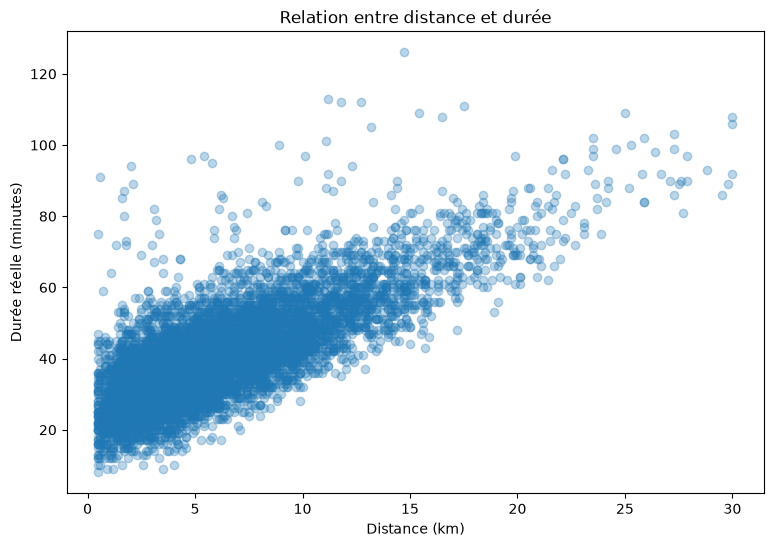

In [197]:
plt.figure(figsize=(9, 6))

plt.scatter(
    donnees_graphique["distance"],
    donnees_graphique["duree_reelle"],
    alpha=0.3
)

plt.xlabel("Distance (km)")
plt.ylabel("Durée réelle (minutes)")
plt.title("Relation entre distance et durée")

plt.show()

In [198]:
print("Lignes X_train :", len(X_train))
print("Lignes y_train :", len(y_train))

print("Indices présents uniquement dans X_train :",
      len(X_train.index.difference(y_train.index)))

print("Indices présents uniquement dans y_train :",
      len(y_train.index.difference(X_train.index)))

print("Même index et même ordre :",
      X_train.index.equals(y_train.index))

Lignes X_train : 6976
Lignes y_train : 6969
Indices présents uniquement dans X_train : 7
Indices présents uniquement dans y_train : 0
Même index et même ordre : False


In [200]:
indices_manquants = X_train.index.difference(y_train.index)

print(indices_manquants)
X_train.loc[indices_manquants]

Index([2045, 2256, 2293, 2632, 3942, 5879, 6118], dtype='int64')


,date_commande,distance_km,nb_arrets,poids_kg,heure_depart,jour_semaine,meteo,type_vehicule,trafic_indice
2045,2025-04-26,3.0,2,8.6,10,samedi,pluie,voiture,2.3
2256,2025-05-07,7.2,1,5.0,19,mercredi,soleil,voiture,5.5
2293,2025-05-08,10.3,4,8.9,21,jeudi,pluie,moto,0.0
2632,2025-05-28,2.5,4,4.7,19,mercredi,pluie,moto,3.4
3942,2025-08-06,11.6,1,11.1,8,mercredi,soleil,voiture,6.6
5879,2025-11-21,1.2,2,6.0,16,vendredi,soleil,voiture,2.6
6118,2025-12-04,4.1,1,8.1,14,jeudi,pluie,voiture,2.6


In [203]:
print(X_train.shape)
print(y_train.shape)

print(X_train.index.equals(y_train.index))

(6976, 9)
(6969,)
False


In [204]:
X_train = X_train.drop(index=indices_manquants)

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("Même index et même ordre :",
      X_train.index.equals(y_train.index))

X_train : (6969, 9)
y_train : (6969,)
Même index et même ordre : True


In [205]:
correlation = X_train["distance_km"].corr(y_train)
print(correlation)

0.7591024193234011


In [206]:
correlations = X_train[
    ["distance_km", "nb_arrets", "poids_kg", "trafic_indice"]
].corrwith(y_train)

print(correlations.sort_values(ascending=False))

distance_km      0.759102
nb_arrets        0.358391
trafic_indice    0.318738
poids_kg         0.045837
dtype: float64


In [210]:
print(X_train.columns.tolist())
print(y_train.name)

['date_commande', 'distance_km', 'nb_arrets', 'poids_kg', 'heure_depart', 'jour_semaine', 'meteo', 'type_vehicule', 'trafic_indice']
duree_reelle_min


In [211]:
donnees_meteo = pd.DataFrame({
    "meteo": X_train["meteo"],
    "duree_reelle_min": y_train
})

resultat_meteo = donnees_meteo.groupby("meteo")["duree_reelle_min"].agg(
    ["count", "mean", "median"]
)

print(resultat_meteo.sort_values("mean", ascending=False))

        count       mean  median
meteo                           
orage     532  49.383459    47.0
pluie    2068  43.142650    41.0
soleil   4369  40.420691    39.0


In [212]:
donnees_vehicule = pd.DataFrame({
    "type_vehicule": X_train["type_vehicule"],
    "duree_reelle_min": y_train
})

resultat_vehicule = donnees_vehicule.groupby("type_vehicule")[
    "duree_reelle_min"
].agg(["count", "mean", "median"])

print(resultat_vehicule.sort_values("mean", ascending=False))

               count       mean  median
type_vehicule                          
camionnette     1075  46.220465    45.0
voiture         2792  42.287607    41.0
moto            3102  40.082205    38.0


In [213]:
donnees_jour = pd.DataFrame({
    "jour_semaine": X_train["jour_semaine"],
    "duree_reelle_min": y_train
})

resultat_jour = donnees_jour.groupby("jour_semaine")[
    "duree_reelle_min"
].agg(["count", "mean", "median"])

print(resultat_jour.sort_values("mean", ascending=False))

              count       mean  median
jour_semaine                          
mercredi        982  43.699593    42.0
mardi           940  42.997872    41.0
vendredi        994  42.747485    41.0
lundi          1001  42.589411    40.0
jeudi           979  42.182840    40.0
samedi         1038  40.109827    38.0
dimanche       1035  39.327536    38.0


In [214]:
print(erreur_validation.describe())

print("Erreur moyenne :", erreur_validation.mean())
print("Erreur absolue moyenne :", erreur_validation.abs().mean())

count    1490.000000
mean        0.056596
std         4.826492
min       -55.987839
25%        -2.043475
50%         0.263428
75%         2.695630
max        14.157440
dtype: float64
Erreur moyenne : 0.056595655425008246
Erreur absolue moyenne : 3.1095551791909073


In [215]:
top_erreurs = erreur_validation.abs().nlargest(5)

print(top_erreurs)

7940    55.987839
7015    53.486853
7705    45.330867
7848    40.972789
7616    38.384806
dtype: float64


In [216]:
for index in top_erreurs.index:
    print(
        f"Index : {index} | "
        f"Réel : {y_validation.loc[index]} min | "
        f"Prédit : {y_barre_val.loc[index]:.2f} min | "
        f"Erreur : {erreur_validation.loc[index]:.2f} min"
    )

Index : 7940 | Réel : 98.0 min | Prédit : 42.01 min | Erreur : -55.99 min
Index : 7015 | Réel : 95.0 min | Prédit : 41.51 min | Erreur : -53.49 min
Index : 7705 | Réel : 88.0 min | Prédit : 42.67 min | Erreur : -45.33 min
Index : 7848 | Réel : 100.0 min | Prédit : 59.03 min | Erreur : -40.97 min
Index : 7616 | Réel : 72.0 min | Prédit : 33.62 min | Erreur : -38.38 min


In [217]:
indices_top = top_erreurs.index

details_erreurs = X_validation.loc[indices_top].copy()

details_erreurs["duree_reelle"] = y_validation.loc[indices_top]
details_erreurs["duree_predite"] = y_barre_val.loc[indices_top]
details_erreurs["erreur"] = erreur_validation.loc[indices_top]

print(details_erreurs)

     date_commande  distance_km  nb_arrets  poids_kg  heure_depart  \
7940    2026-03-12          4.0          5       2.4            16   
7015    2026-01-21          5.2          1       7.3             8   
7705    2026-02-28          9.2          1       6.5            17   
7848    2026-03-07         10.1          3       1.5            17   
7616    2026-02-23          5.8          1       2.2             7   

     jour_semaine   meteo type_vehicule  trafic_indice  duree_reelle  \
7940        jeudi  soleil   camionnette            2.2          98.0   
7015     mercredi   pluie       voiture            6.0          95.0   
7705       samedi  soleil       voiture            4.0          88.0   
7848       samedi   pluie   camionnette            4.5         100.0   
7616        lundi  soleil          moto            4.7          72.0   

      duree_predite     erreur  
7940      42.012161 -55.987839  
7015      41.513147 -53.486853  
7705      42.669133 -45.330867  
7848      59.0

In [218]:
print(
    y_train.describe(percentiles=[0.90, 0.95, 0.99])

    
)
print("Livraisons supérieures à 77 min :", (y_train > 77).sum())
print("Livraisons supérieures à 90 min :", (y_train > 90).sum())
print("Livraisons supérieures à 100 min :", (y_train > 100).sum())


count    6969.000000
mean       41.912613
std        14.409252
min         8.000000
90%        61.000000
95%        68.000000
99%        85.320000
max       126.000000
Name: duree_reelle_min, dtype: float64
Livraisons supérieures à 77 min : 142
Livraisons supérieures à 90 min : 42
Livraisons supérieures à 100 min : 15


In [219]:
indices_extremes = y_train[y_train > 100].index

details_extremes = X_train.loc[indices_extremes].copy()
details_extremes["duree_reelle"] = y_train.loc[indices_extremes]

print(details_extremes.sort_values("duree_reelle", ascending=False))

     date_commande  distance_km  nb_arrets  poids_kg  heure_depart  \
5770    2025-11-16         14.7          7       2.9            18   
2584    2025-05-25         11.2          3       4.7            18   
3443    2025-07-10         11.8          3       9.9            17   
6493    2025-12-24         12.7          1       2.2            18   
4384    2025-08-30         17.5          4       4.6            18   
4453    2025-09-03         15.4          4      14.3            16   
1633    2025-04-03         25.0          7       3.9            13   
5082    2025-10-09         16.5          6       7.5            18   
4803    2025-09-23         30.0          2      12.2            17   
850     2025-02-19         30.0          2       2.6            17   
4841    2025-09-24         13.2          4       5.9            14   
6595    2025-12-29         27.3          5       2.7             8   
337     2025-01-21         23.5          4      12.6             8   
1044    2025-03-02  

In [220]:
livraisons = pd.DataFrame({
    "distance_km": X_train["distance_km"],
    "duree_reelle": y_train
})

livraisons["categorie"] = np.where(
    livraisons["duree_reelle"] > 77,
    "Livraisons longues",
    "Livraisons habituelles"
)

print(
    livraisons.groupby("categorie")["distance_km"]
    .agg(["count", "mean", "median", "min", "max"])
)

                        count       mean  median  min   max
categorie                                                  
Livraisons habituelles   6816   6.336253     5.6  0.5  23.9
Livraisons longues        141  17.873759    18.4  0.6  30.0


In [221]:
livraisons_courtes_longues = livraisons[
    (livraisons["duree_reelle"] > 77) &
    (livraisons["distance_km"] < 5)
]

print(livraisons_courtes_longues)

      distance_km  duree_reelle           categorie
1094          4.8          96.0  Livraisons longues
2661          0.6          91.0  Livraisons longues
2874          1.6          85.0  Livraisons longues
3378          3.2          79.0  Livraisons longues
5230          3.1          82.0  Livraisons longues
5370          2.0          94.0  Livraisons longues
6701          1.7          80.0  Livraisons longues
6830          2.1          89.0  Livraisons longues
6838          1.7          87.0  Livraisons longues


In [222]:
indices_courtes_longues = livraisons_courtes_longues.index

details_courtes_longues = X_train.loc[
    indices_courtes_longues
].copy()

details_courtes_longues["duree_reelle"] = y_train.loc[
    indices_courtes_longues
]

print(details_courtes_longues)

     date_commande  distance_km  nb_arrets  poids_kg  heure_depart  \
1094    2025-03-04          4.8          1       8.5            17   
2661    2025-05-30          0.6          1      11.4            19   
2874    2025-06-09          1.6          4       3.5            19   
3378    2025-07-07          3.2          3       5.9            20   
5230    2025-10-18          3.1          7      16.8            14   
5370    2025-10-25          2.0          6      22.0            16   
6701    2026-01-05          1.7          7      11.6            11   
6830    2026-01-11          2.1          3       6.2             8   
6838    2026-01-12          1.7          1       3.4            17   

     jour_semaine   meteo type_vehicule  trafic_indice  duree_reelle  
1094        mardi  soleil       voiture            5.7          96.0  
2661     vendredi  soleil       voiture            5.3          91.0  
2874        lundi  soleil          moto            5.9          85.0  
3378        lun

In [223]:
print(y_train.loc[indices_courtes_longues].describe())
print(
    y_train.loc[indices_courtes_longues]
    .sort_values(ascending=False)
)

count     9.000000
mean     87.000000
std       6.041523
min      79.000000
25%      82.000000
50%      87.000000
75%      91.000000
max      96.000000
Name: duree_reelle_min, dtype: float64
1094    96.0
5370    94.0
2661    91.0
6830    89.0
6838    87.0
2874    85.0
5230    82.0
6701    80.0
3378    79.0
Name: duree_reelle_min, dtype: float64


In [224]:
analyse_residus = pd.DataFrame({
    "duree_reelle": y_validation,
    "erreur": erreur_validation
})

analyse_residus["tranche"] = pd.cut(
    analyse_residus["duree_reelle"],
    bins=[0, 20, 40, 60, 80, 100, 130]
)

resultat_residus = analyse_residus.groupby(
    "tranche", observed=False
)["erreur"].agg(
    ["count", "mean", "median"]
)

resultat_residus["MAE"] = analyse_residus.groupby(
    "tranche", observed=False
)["erreur"].apply(lambda x: x.abs().mean())

print(resultat_residus)

            count       mean     median        MAE
tranche                                           
(0, 20]        61   3.801415   3.581518   4.128366
(20, 40]      698   0.821380   0.658862   2.884160
(40, 60]      577  -0.321606  -0.153099   2.710468
(60, 80]      125  -1.885355  -1.579915   3.821233
(80, 100]      27 -10.084367  -3.011802  10.827093
(100, 130]      2 -13.684053 -13.684053  17.168708


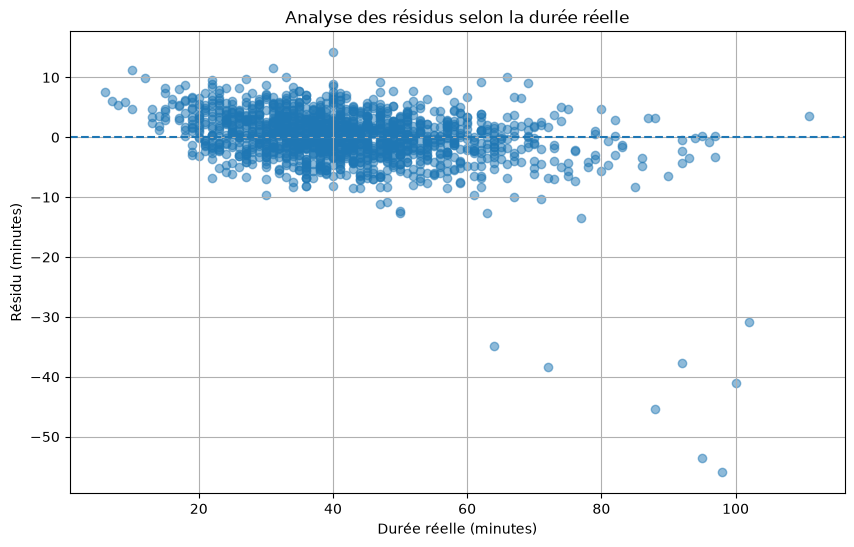

In [225]:
plt.figure(figsize=(10, 6))

plt.scatter(
    analyse_residus["duree_reelle"],
    analyse_residus["erreur"],
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Durée réelle (minutes)")
plt.ylabel("Résidu (minutes)")
plt.title("Analyse des résidus selon la durée réelle")

plt.grid(True)
plt.show()

In [228]:
X_train.select_dtypes(include="number").corrwith(y_train).sort_values(ascending=False)

distance_km      0.759102
nb_arrets        0.358391
trafic_indice    0.318738
poids_kg         0.045837
heure_depart    -0.006920
dtype: float64

Nouveau modele pour etre capable de predire les distances longues

In [234]:
# Copies des matrices originales
X_train_fe = X_train_final.copy()
X_validation_fe = X_validation_final.copy()

# 1. Terme polynomial : distance au carré
X_train_fe["distance_km_carre"] = X_train_final["distance_km"] ** 2

X_validation_fe["distance_km_carre"] = (
    X_validation_final["distance_km"] ** 2
)

# 2. Interaction : distance × trafic
X_train_fe["distance_trafic"] = (
    X_train_final["distance_km"] * X_train_final["trafic_indice"]
)

X_validation_fe["distance_trafic"] = (
    X_validation_final["distance_km"] * X_validation_final["trafic_indice"]
)

# 3. Interaction : distance × nombre d'arrêts
X_train_fe["distance_arrets"] = (
    X_train_final["distance_km"] * X_train_final["nb_arrets"]
)

X_validation_fe["distance_arrets"] = (
    X_validation_final["distance_km"] * X_validation_final["nb_arrets"]
)

# Vérification
print("Train :", X_train_fe.shape)
print("Validation :", X_validation_fe.shape)
print(X_train_fe[[
    "distance_km",
    "distance_km_carre",
    "distance_trafic",
    "distance_arrets"
]].head())

Train : (6969, 21)
Validation : (1490, 21)
    distance_km  distance_km_carre  distance_trafic  distance_arrets
0      0.439514           0.193173         0.606782        -0.442149
13     0.098203           0.009644         0.111733         0.017959
12     3.261021          10.634255        -0.565146         0.596366
11     0.576038           0.331820        -0.295631        -0.579492
10     0.143711           0.020653         0.184447         0.111708


Normaliser les nouvelles caractéristiques
Regarde tes résultats : distance_km_carre atteint déjà 10,63, alors que distance_km vaut 3,26 sur cette ligne.
Les échelles des variables sont donc différentes.
Or, notre descente de gradient utilise un taux d'apprentissage commun. Des variables ayant des amplitudes très différentes peuvent rendre l'optimisation plus difficile.
Nous allons donc standardiser les trois nouvelles colonnes.


In [235]:
nouvelles_features = [
    "distance_km_carre",
    "distance_trafic",
    "distance_arrets"
]

# Moyennes et écarts-types calculés sur le train
moyennes_fe = X_train_fe[nouvelles_features].mean()
ecarts_types_fe = X_train_fe[nouvelles_features].std()

# Standardisation du train
X_train_fe[nouvelles_features] = (
    X_train_fe[nouvelles_features] - moyennes_fe
) / ecarts_types_fe

# Standardisation de la validation avec les statistiques du train
X_validation_fe[nouvelles_features] = (
    X_validation_fe[nouvelles_features] - moyennes_fe
) / ecarts_types_fe

# Vérification
print(X_train_fe[nouvelles_features].agg(["mean", "std"]))
print("\nValidation :")
print(X_validation_fe[nouvelles_features].head())

      distance_km_carre  distance_trafic  distance_arrets
mean       8.921293e-18    -1.045066e-17    -6.117458e-18
std        1.000000e+00     1.000000e+00     1.000000e+00

Validation :
      distance_km_carre  distance_trafic  distance_arrets
6990           0.061572         1.450460        -0.206490
6991          -0.027189        -1.047909        -0.189945
6998          -0.055729         0.781436         2.379423
6997           0.038637        -0.025345         1.026070
6994          -0.163402        -1.304715         0.798538


In [237]:
# Conversion en matrices NumPy
X_train_fe_np = X_train_fe.to_numpy(dtype=float)
X_validation_fe_np = X_validation_fe.to_numpy(dtype=float)

y_train_np = y_train.to_numpy(dtype=float)
y_validation_np = y_validation.to_numpy(dtype=float)

# Dimensions
m, n = X_train_fe_np.shape

# Initialisation des paramètres
W_fe = np.zeros(n)
b_fe = 0.0

print("X_train :", X_train_fe_np.shape)
print("X_validation :", X_validation_fe_np.shape)
print("W :", W_fe.shape)
print("b : ", b_fe)

X_train : (6969, 21)
X_validation : (1490, 21)
W : (21,)
b :  0.0


In [238]:
alpha_fe = 0.1
iterations_fe = 1000
epsilon_fe = 1e-8

historique_cout_fe = []
cout_precedent_fe = None

for i in range(iterations_fe):

    #Prédictions
    y_pred_fe = X_train_fe_np @ W_fe + b_fe

    #Erreurs
    erreurs_fe = y_pred_fe - y_train_np

    #Fonction coût
    cout_fe = np.sum(erreurs_fe ** 2) / (2 * m)

    #Gradients
    dW_fe = (X_train_fe_np.T @ erreurs_fe) / m
    db_fe = np.sum(erreurs_fe) / m

    #Mise a jour
    W_fe -= alpha_fe * dW_fe
    b_fe -= alpha_fe * db_fe

    #Historique
    historique_cout_fe.append(cout_fe)

    #Vérification de convergence
    if cout_precedent_fe is not None:
        variation_fe = abs(cout_precedent_fe - cout_fe)

        if variation_fe < epsilon_fe:
            print(f"Convergence atteinte à l'itération {i + 1}")
            break

    cout_precedent_fe = cout_fe

print("Coût final :", historique_cout_fe[-1])
print("Nombre d'itérations :", len(historique_cout_fe))

Convergence atteinte à l'itération 854
Coût final : 14.26446364067414
Nombre d'itérations : 854


In [239]:
#Prédictions sur la validation
y_pred_validation_fe = X_validation_fe_np @ W_fe + b_fe

#Erreurs
erreurs_validation_fe = y_pred_validation_fe - y_validation_np

#Métriques
mae_fe = np.mean(np.abs(erreurs_validation_fe))
rmse_fe = np.sqrt(np.mean(erreurs_validation_fe ** 2))

ss_res_fe = np.sum((y_validation_np - y_pred_validation_fe) ** 2)
ss_tot_fe = np.sum((y_validation_np - np.mean(y_validation_np)) ** 2)

r2_fe = 1 - (ss_res_fe / ss_tot_fe)

print("MAE :", mae_fe)
print("RMSE :", rmse_fe)
print("R² :", r2_fe)

MAE : 3.109948588621755
RMSE : 4.825729010742383
R² : 0.8911274912472006


In [240]:
#Identifier les livraisons longues dans la validation
mask_longues = y_validation_np > 77

#MAE du nouveau modèle sur les livraisons longues
mae_longues_fe = np.mean(
    np.abs(erreurs_validation_fe[mask_longues])
)

#Erreur moyenne signée
erreur_moyenne_longues_fe = np.mean(
    erreurs_validation_fe[mask_longues]
)

print("Nombre de livraisons longues :", np.sum(mask_longues))
print("MAE livraisons longues :", mae_longues_fe)
print("Erreur moyenne signée :", erreur_moyenne_longues_fe)

Nombre de livraisons longues : 37
MAE livraisons longues : 9.558325383472397
Erreur moyenne signée : -8.376241180561639


In [ ]:
# Copier les matrices originales
X_train_quad = X_train_final.copy()
X_validation_quad = X_validation_final.copy()

# Ajouter uniquement la feature quadratique déjà créée et standardisée
X_train_quad["distance_km_carre"] = X_train_fe["distance_km_carre"]
X_validation_quad["distance_km_carre"] = X_validation_fe["distance_km_carre"]

# Convertir en tableaux NumPy
X_train_quad_np = X_train_quad.to_numpy(dtype=float)
X_validation_quad_np = X_validation_quad.to_numpy(dtype=float)

# Dimensions
m_quad, n_quad = X_train_quad_np.shape

print("Train :", X_train_quad_np.shape)
print("Validation :", X_validation_quad_np.shape)
print("Nombre de paramètres :", n_quad)

In [242]:
print("X_test_final :", X_test_final.shape)
print("y_test :", y_test.shape)

X_test_final : (1506, 18)
y_test : (1506,)


In [243]:
#Prédictions sur les données de test
y_pred_test = X_test_final.to_numpy(dtype=float) @ W_iter + b_iter

#Vérifier les dimensions
print("Prédictions :", y_pred_test.shape)
print("Valeurs réelles :", y_test.shape)

#Afficher quelques prédictions
for i in range(5):
    print(
        f"Livraison {i+1} | "
        f"Prédiction : {y_pred_test[i]:.2f} min | "
        f"Réel : {y_test.iloc[i]:.2f} min"
    )

Prédictions : (1506,)
Valeurs réelles : (1506,)
Livraison 1 | Prédiction : 27.87 min | Réel : 29.00 min
Livraison 2 | Prédiction : 35.29 min | Réel : 35.00 min
Livraison 3 | Prédiction : 49.81 min | Réel : 49.00 min
Livraison 4 | Prédiction : 27.78 min | Réel : 23.00 min
Livraison 5 | Prédiction : 18.14 min | Réel : 13.00 min


In [244]:
#Convertir la cible en NumPy
y_test_np = y_test.to_numpy(dtype=float)

#MAE
mae_test = np.mean(np.abs(y_pred_test - y_test_np))

#RMSE
rmse_test = np.sqrt(np.mean((y_pred_test - y_test_np) ** 2))

#R²
ss_res_test = np.sum((y_test_np - y_pred_test) ** 2)
ss_tot_test = np.sum((y_test_np - np.mean(y_test_np)) ** 2)

r2_test = 1 - (ss_res_test / ss_tot_test)

print("MAE test :", mae_test)
print("RMSE test :", rmse_test)
print("R² test :", r2_test)

MAE test : 3.2710756033230655
RMSE test : 5.628653210189619
R² test : 0.8549187051085961


In [245]:
#Calcul des erreurs
erreurs_test = y_pred_test - y_test_np

#Identifier les livraisons longues
mask_longues_test = y_test_np > 77

#Nombre de livraisons longues
nombre_longues_test = np.sum(mask_longues_test)

#MAE des livraisons longues
mae_longues_test = np.mean(
    np.abs(erreurs_test[mask_longues_test])
)

#Erreur moyenne signée
erreur_signee_longues_test = np.mean(
    erreurs_test[mask_longues_test]
)

print("Nombre de livraisons longues :", nombre_longues_test)
print("MAE livraisons longues :", mae_longues_test)
print("Erreur moyenne signée :", erreur_signee_longues_test)

Nombre de livraisons longues : 37
MAE livraisons longues : 14.761300553697083
Erreur moyenne signée : -13.115504347049898


In [281]:
df_predictions = pd.read_csv("livraisons_a_predire_500_propre.csv")

print("Dimensions :", df_predictions.shape)
print("Colonnes :")
print(df_predictions.columns.tolist())

display(df_predictions.head())

Dimensions : (500, 10)
Colonnes :
['id_livraison', 'date_commande', 'distance_km', 'nb_arrets', 'poids_kg', 'heure_depart', 'jour_semaine', 'meteo', 'type_vehicule', 'trafic_indice']


,id_livraison,date_commande,distance_km,nb_arrets,poids_kg,heure_depart,jour_semaine,meteo,type_vehicule,trafic_indice
0,100001,2026-07-01,8.7,1,3.3,8,mercredi,pluie,moto,5.6
1,100002,2026-07-01,3.7,2,6.7,12,mercredi,soleil,voiture,0.9
2,100003,2026-07-01,4.3,2,6.9,13,mercredi,soleil,voiture,2.0
3,100004,2026-07-01,1.6,1,13.2,10,mercredi,orage,moto,2.2
4,100005,2026-07-01,1.2,0,10.4,20,mercredi,pluie,voiture,1.1


In [282]:
print("Colonnes finales du modèle :")
print(X_train_final.columns.tolist())

print("Objets disponibles pour le prétraitement :")
print([
    nom for nom in globals()
    if any(mot in nom.lower() for mot in [
        "scaler", "moyenne", "ecart", "encoder",
        "onehot", "categories"
    ])
])

Colonnes finales du modèle :
['distance_km', 'nb_arrets', 'poids_kg', 'heure_depart', 'trafic_indice', 'jour_semaine_dimanche', 'jour_semaine_jeudi', 'jour_semaine_lundi', 'jour_semaine_mardi', 'jour_semaine_mercredi', 'jour_semaine_samedi', 'jour_semaine_vendredi', 'meteo_orage', 'meteo_pluie', 'meteo_soleil', 'type_vehicule_camionnette', 'type_vehicule_moto', 'type_vehicule_voiture']
Objets disponibles pour le prétraitement :
['OneHotEncoder', 'encoder', 'StandardScaler', 'scaler', 'duree_moyenne', 'moyenne_y_validation', 'erreur_moyenne', 'erreur_moyenne_carre', 'moyennes_fe', 'ecarts_types_fe', 'erreur_moyenne_longues_fe']


In [283]:
print("SCALER")

print("Moyennes :", scaler.mean_)
print("Écarts-types :", scaler.scale_)
print("Nombre de variables :", scaler.n_features_in_)

print("ENCODER")

print("Nombre de variables :", encoder.n_features_in_)
print("Noms des variables :", getattr(encoder, "feature_names_in_", "Non disponibles"))
print("Catégories :", encoder.categories_)

SCALER
Moyennes : [ 6.56841728  2.69235184  6.23403645 13.3902999   3.45689482]
Écarts-types : [4.39481521 1.68226603 4.87287004 4.25470432 2.05936403]
Nombre de variables : 5
ENCODER
Nombre de variables : 3
Noms des variables : ['jour_semaine' 'meteo' 'type_vehicule']
Catégories : [array(['dimanche', 'jeudi', 'lundi', 'mardi', 'mercredi', 'samedi',
       'vendredi'], dtype=object), array(['orage', 'pluie', 'soleil'], dtype=object), array(['camionnette', 'moto', 'voiture'], dtype=object)]


In [252]:
# Copier les données pour préserver le fichier original
df_predictions_prepare = df_predictions.copy()

# Retirer l'identifiant des variables explicatives
X_predictions_brut = df_predictions_prepare.drop(
    columns=["id_livraison", "date_commande"]
)

# Séparer les variables numériques
colonnes_numeriques = [
    "distance_km",
    "nb_arrets",
    "poids_kg",
    "heure_depart",
    "trafic_indice"
]

X_predictions_num = scaler.transform(
    X_predictions_brut[colonnes_numeriques]
)

X_predictions_num = pd.DataFrame(
    X_predictions_num,
    columns=colonnes_numeriques,
    index=df_predictions.index
)

# Séparer les variables catégorielles
colonnes_categorielles = [
    "jour_semaine",
    "meteo",
    "type_vehicule"
]

X_predictions_cat = encoder.transform(
    X_predictions_brut[colonnes_categorielles]
)

X_predictions_cat = pd.DataFrame(
    X_predictions_cat,
    columns=encoder.get_feature_names_out(colonnes_categorielles),
    index=df_predictions.index
)

# Fusionner les variables
X_predictions_final = pd.concat(
    [X_predictions_num, X_predictions_cat],
    axis=1
)

# Respecter exactement l'ordre des 18 features du modèle
X_predictions_final = X_predictions_final[
    X_train_final.columns
]

print("Dimensions :", X_predictions_final.shape)
print("Colonnes :", X_predictions_final.columns.tolist())

Dimensions : (500, 18)
Colonnes : ['distance_km', 'nb_arrets', 'poids_kg', 'heure_depart', 'trafic_indice', 'jour_semaine_dimanche', 'jour_semaine_jeudi', 'jour_semaine_lundi', 'jour_semaine_mardi', 'jour_semaine_mercredi', 'jour_semaine_samedi', 'jour_semaine_vendredi', 'meteo_orage', 'meteo_pluie', 'meteo_soleil', 'type_vehicule_camionnette', 'type_vehicule_moto', 'type_vehicule_voiture']


/home/germain/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [253]:
print("Valeurs manquantes :",
      X_predictions_final.isna().sum().sum())

print("Valeurs infinies :",
      np.isinf(X_predictions_final.to_numpy()).sum())

print("Dimensions :",
      X_predictions_final.shape)

print("Ordre des features correct :",
      X_predictions_final.columns.equals(X_train_final.columns))

Valeurs manquantes : 0
Valeurs infinies : 0
Dimensions : (500, 18)
Ordre des features correct : True


In [254]:
# Convertir les features en NumPy
X_predictions_np = X_predictions_final.to_numpy(dtype=float)

# Effectuer les prédictions
y_predictions_500 = X_predictions_np @ W_iter + b_iter

# Vérifier les résultats
print("Nombre de prédictions :", len(y_predictions_500))
print("Premières prédictions :")

for i in range(5):
    print(
        f"Livraison {df_predictions['id_livraison'].iloc[i]} : "
        f"{y_predictions_500[i]:.2f} minutes"
    )

print("\nDurée minimale prédite :", y_predictions_500.min())
print("Durée maximale prédite :", y_predictions_500.max())
print("Durée moyenne prédite :", y_predictions_500.mean())

Nombre de prédictions : 500
Premières prédictions :
Livraison 100001 : 46.82 minutes
Livraison 100002 : 25.72 minutes
Livraison 100003 : 29.69 minutes
Livraison 100004 : 29.50 minutes
Livraison 100005 : 18.21 minutes

Durée minimale prédite : -19.048357437576083
Durée maximale prédite : 2517.172472811873
Durée moyenne prédite : 80.5084076244494


In [284]:
#Créer un tableau de diagnostic
diagnostic_predictions = df_predictions[
    ["id_livraison", "distance_km", "nb_arrets",
     "poids_kg", "heure_depart", "trafic_indice"]
].copy()

diagnostic_predictions["duree_predite"] = y_predictions_500

#Trier par durée prédite
print("10 PLUS PETITES PRÉDICTIONS")
display(
    diagnostic_predictions.nsmallest(10, "duree_predite")
)

print("10 PLUS GRANDES PRÉDICTIONS")
display(
    diagnostic_predictions.nlargest(10, "duree_predite")
)

10 PLUS PETITES PRÉDICTIONS


,id_livraison,distance_km,nb_arrets,poids_kg,heure_depart,trafic_indice,duree_predite
353,100354,0.8,1,5.5,12,1.2,13.968714
157,100158,1.2,1,6.4,13,1.2,14.454982
261,100262,-0.6,1,17.0,14,1.9,16.428916
72,100073,1.9,1,16.5,12,0.6,16.640836
51,100052,1.6,2,1.8,20,0.0,17.369641
194,100195,1.2,2,3.4,13,1.6,17.657529
4,100005,1.2,0,10.4,20,1.1,18.205124
59,100060,1.5,1,13.7,15,1.9,19.361276
99,100100,1.6,2,2.4,6,1.7,19.632503
399,100400,3.3,2,3.5,11,0.0,19.661918


10 PLUS GRANDES PRÉDICTIONS


,id_livraison,distance_km,nb_arrets,poids_kg,heure_depart,trafic_indice,duree_predite
479,100480,29.8,1,1.4,8,5.1,98.226827
354,100355,21.1,7,3.3,12,1.1,91.756699
437,100438,18.4,2,2.0,9,6.3,87.794895
127,100128,19.0,2,3.4,18,6.8,84.371286
429,100430,22.0,5,1.9,8,3.9,84.245740
185,100186,28.0,1,16.0,15,2.0,83.794894
162,100163,20.4,5,7.2,15,0.0,82.214543
401,100402,15.9,3,7.9,8,4.7,81.217286
65,100066,20.6,4,2.9,11,2.3,80.125095
277,100278,20.8,5,3.7,7,2.9,78.702506


In [285]:
print("CONTRÔLE DES DISTANCES")

print("Distances négatives :",
      (df_predictions["distance_km"] < 0).sum())

print("Distances égales à zéro :",
      (df_predictions["distance_km"] == 0).sum())

print("Distances supérieures à 77 km :",
      (df_predictions["distance_km"] > 77).sum())

print("Statistiques des distances :")
print(df_predictions["distance_km"].describe())

CONTRÔLE DES DISTANCES
Distances négatives : 12
Distances égales à zéro : 0
Distances supérieures à 77 km : 8
Statistiques des distances :
count    500.00000
mean      22.18780
std      124.78424
min      -17.40000
25%        3.17500
50%        5.50000
75%        8.70000
max      999.00000
Name: distance_km, dtype: float64


In [257]:
# Identifier les distances négatives ou très élevées
mask_anomalies_distance = (
    (df_predictions["distance_km"] < 0) |
    (df_predictions["distance_km"] > 77)
)

colonnes_a_afficher = [
    "id_livraison",
    "distance_km",
    "nb_arrets",
    "poids_kg",
    "heure_depart",
    "jour_semaine",
    "meteo",
    "type_vehicule",
    "trafic_indice"
]

display(
    df_predictions.loc[
        mask_anomalies_distance,
        colonnes_a_afficher
    ].sort_values("distance_km")
)

,id_livraison,distance_km,nb_arrets,poids_kg,heure_depart,jour_semaine,meteo,type_vehicule,trafic_indice
235,100236,-17.4,1,12.9,12,mercredi,pluie,camionnette,2.0
102,100103,-11.0,3,5.2,12,mercredi,soleil,moto,2.6
115,100116,-10.2,4,13.6,18,mercredi,orage,moto,5.7
192,100193,-8.4,7,15.9,12,dimanche,soleil,camionnette,0.0
466,100467,-7.4,2,3.4,13,mercredi,soleil,voiture,2.7
70,100071,-6.1,2,4.0,17,lundi,soleil,moto,6.8
220,100221,-5.6,3,1.7,18,mardi,soleil,voiture,5.1
124,100125,-4.7,1,3.5,17,jeudi,soleil,voiture,5.0
216,100217,-3.3,4,5.6,14,mardi,soleil,voiture,3.5
326,100327,-2.3,3,6.4,19,mardi,pluie,moto,6.8


In [289]:
print("DISTANCES DU TRAIN")

print("Minimum :", X_train["distance_km"].min())
print("Maximum :", X_train["distance_km"].max())

print("DISTANCES DES 500 LIVRAISONS")

print("Minimum :", df_predictions["distance_km"].min())
print("Maximum :", df_predictions["distance_km"].max())

DISTANCES DU TRAIN
Minimum : 0.5
Maximum : 30.0
DISTANCES DES 500 LIVRAISONS
Minimum : -17.4
Maximum : 999.0


In [287]:
mask_distances_invalides = (
    (df_predictions["distance_km"] < 0) |
    (df_predictions["distance_km"] > 30)
)

lignes_invalides = df_predictions.loc[mask_distances_invalides]

print("Nombre de lignes à régénérer :", len(lignes_invalides))

display(lignes_invalides)

Nombre de lignes à régénérer : 20


,id_livraison,date_commande,distance_km,nb_arrets,poids_kg,heure_depart,jour_semaine,meteo,type_vehicule,trafic_indice
70,100071,2026-07-06,-6.1,2,4.0,17,lundi,soleil,moto,6.8
102,100103,2026-07-08,-11.0,3,5.2,12,mercredi,soleil,moto,2.6
115,100116,2026-07-08,-10.2,4,13.6,18,mercredi,orage,moto,5.7
124,100125,2026-07-09,-4.7,1,3.5,17,jeudi,soleil,voiture,5.0
188,100189,2026-07-12,999.0,4,1.5,13,dimanche,pluie,voiture,3.5
192,100193,2026-07-12,-8.4,7,15.9,12,dimanche,soleil,camionnette,0.0
216,100217,2026-07-14,-3.3,4,5.6,14,mardi,soleil,voiture,3.5
220,100221,2026-07-14,-5.6,3,1.7,18,mardi,soleil,voiture,5.1
229,100230,2026-07-15,999.0,2,1.5,18,mercredi,soleil,voiture,4.4
235,100236,2026-07-15,-17.4,1,12.9,12,mercredi,pluie,camionnette,2.0


In [260]:
mediane_distance_train = X_train["distance_km"].median()

print("Médiane des distances d'entraînement :", mediane_distance_train)

Médiane des distances d'entraînement : 5.6


In [261]:
a_predire = df_predictions.copy()

# Identifier les anomalies
neg = a_predire["distance_km"] < 0
code_erreur = a_predire["distance_km"] >= 100

# Créer une colonne de distance corrigée
a_predire["distance_corrigee"] = a_predire["distance_km"]

# Règle 1 : corriger le signe des distances négatives
a_predire.loc[neg, "distance_corrigee"] = (
    a_predire.loc[neg, "distance_km"].abs()
)

# Règle 2 : imputer les distances codées à 999
a_predire.loc[code_erreur, "distance_corrigee"] = mediane_distance_train

# Tracer les observations corrigées
a_predire["distance_estimee"] = (
    neg | code_erreur
).astype(int)

print("Distances corrigées :", int(a_predire["distance_estimee"].sum()))
print("Distance minimale :", a_predire["distance_corrigee"].min())
print("Distance maximale :", a_predire["distance_corrigee"].max())

display(
    a_predire.loc[
        a_predire["distance_estimee"] == 1,
        ["id_livraison", "distance_km", "distance_corrigee", "distance_estimee"]
    ]
)

Distances corrigées : 20
Distance minimale : 0.5
Distance maximale : 29.8


,id_livraison,distance_km,distance_corrigee,distance_estimee
70,100071,-6.1,6.1,1
102,100103,-11.0,11.0,1
115,100116,-10.2,10.2,1
124,100125,-4.7,4.7,1
188,100189,999.0,5.6,1
192,100193,-8.4,8.4,1
216,100217,-3.3,3.3,1
220,100221,-5.6,5.6,1
229,100230,999.0,5.6,1
235,100236,-17.4,17.4,1


In [290]:
# Vérifier les valeurs manquantes
print("Valeurs manquantes :")
print(a_predire.isna().sum())

# Vérifier les valeurs infinies dans les colonnes numériques
colonnes_num = [
    "distance_corrigee",
    "nb_arrets",
    "poids_kg",
    "heure_depart",
    "trafic_indice"
]

print("\nValeurs infinies :")
print(
    np.isinf(a_predire[colonnes_num].to_numpy(dtype=float)).sum()
)

# Vérifier les catégories
for colonne in ["jour_semaine", "meteo", "type_vehicule"]:
    print(f"Valeurs uniques de {colonne} :")
    print(sorted(a_predire[colonne].dropna().unique()))

Valeurs manquantes :
id_livraison         0
date_commande        0
distance_km          0
nb_arrets            0
poids_kg             0
heure_depart         0
jour_semaine         0
meteo                0
type_vehicule        0
trafic_indice        0
distance_corrigee    0
distance_estimee     0
dtype: int64

Valeurs infinies :
0
Valeurs uniques de jour_semaine :
['dimanche', 'jeudi', 'lundi', 'mardi', 'mercredi', 'samedi', 'vendredi']
Valeurs uniques de meteo :
['orage', 'pluie', 'soleil']
Valeurs uniques de type_vehicule :
['camionnette', 'moto', 'voiture']


In [291]:
#Préparer les données
X_predictions_brut = a_predire.drop(
    columns=[
        "id_livraison",
        "date_commande",
        "distance_km",
        "distance_estimee"
    ]
).copy()

#Renommer la distance corrigée
X_predictions_brut = X_predictions_brut.rename(
    columns={"distance_corrigee": "distance_km"}
)

#Variables numériques
colonnes_numeriques = [
    "distance_km",
    "nb_arrets",
    "poids_kg",
    "heure_depart",
    "trafic_indice"
]

X_predictions_num = scaler.transform(
    X_predictions_brut[colonnes_numeriques].to_numpy()
)

X_predictions_num = pd.DataFrame(
    X_predictions_num,
    columns=colonnes_numeriques,
    index=a_predire.index
)

#Variables catégorielles
colonnes_categorielles = [
    "jour_semaine",
    "meteo",
    "type_vehicule"
]

X_predictions_cat = encoder.transform(
    X_predictions_brut[colonnes_categorielles]
)

X_predictions_cat = pd.DataFrame(
    X_predictions_cat,
    columns=encoder.get_feature_names_out(
        colonnes_categorielles
    ),
    index=a_predire.index
)

#Fusionner
X_predictions_final = pd.concat(
    [X_predictions_num, X_predictions_cat],
    axis=1
)

#Garantir le même ordre que pendant l'entraînement
X_predictions_final = X_predictions_final[X_train_final.columns]

print("Dimensions :", X_predictions_final.shape)
print("Colonnes identiques :", 
      list(X_predictions_final.columns) == list(X_train_final.columns))
print("Valeurs manquantes :", X_predictions_final.isna().sum().sum())

Dimensions : (500, 18)
Colonnes identiques : True
Valeurs manquantes : 0


In [292]:
#Convertir les features en matrice NumPy
X_predictions_np = X_predictions_final.to_numpy(dtype=float)

#Effectuer les prédictions avec le modèle entraîné
y_predictions_500 = X_predictions_np @ W_iter + b_iter

print("Nombre de prédictions :", len(y_predictions_500))
print("Prédiction minimale :", y_predictions_500.min())
print("Prédiction maximale :", y_predictions_500.max())
print("Prédiction moyenne :", y_predictions_500.mean())

Nombre de prédictions : 500
Prédiction minimale : 13.968713679039803
Prédiction maximale : 98.22682733278056
Prédiction moyenne : 41.7363705410103


In [265]:
resultats_predictions = pd.DataFrame({
    "id_livraison": a_predire["id_livraison"],
    "distance_km_originale": a_predire["distance_km"],
    "distance_km_utilisee": a_predire["distance_corrigee"],
    "distance_estimee": a_predire["distance_estimee"],
    "duree_predite_min": y_predictions_500
})

display(resultats_predictions.head())

,id_livraison,distance_km_originale,distance_km_utilisee,distance_estimee,duree_predite_min
0,100001,8.7,8.7,0,46.820199
1,100002,3.7,3.7,0,25.719620
2,100003,4.3,4.3,0,29.692022
3,100004,1.6,1.6,0,29.499823
4,100005,1.2,1.2,0,18.205124


In [294]:
#Construire le tableau complet des résultats
resultats_predictions = pd.DataFrame({
    "id_livraison": a_predire["id_livraison"],
    "distance_km_originale": a_predire["distance_km"],
    "distance_km_utilisee": a_predire["distance_corrigee"],
    "distance_estimee": a_predire["distance_estimee"],
    "duree_predite_min": y_predictions_500
})

#Comparer les prédictions selon le statut de correction
print("PRÉDICTIONS SELON LE STATUT DES DISTANCES")

display(
    resultats_predictions.groupby("distance_estimee")[
        "duree_predite_min"
    ].agg(["count", "mean", "median", "min", "max"])
)

#Les 10 prédictions les plus élevées
print("=== 10 DURÉES PRÉDITES LES PLUS ÉLEVÉES ===")

display(
    resultats_predictions.nlargest(10, "duree_predite_min")
)

#Les 10 prédictions les plus faibles
print("=== 10 DURÉES PRÉDITES LES PLUS FAIBLES ===")

display(
    resultats_predictions.nsmallest(10, "duree_predite_min")
)

PRÉDICTIONS SELON LE STATUT DES DISTANCES


,count,mean,median,min,max
distance_estimee,,,,,
0,480,41.784744,39.706787,13.968714,98.226827
1,20,40.575409,38.142366,16.428916,67.911794


=== 10 DURÉES PRÉDITES LES PLUS ÉLEVÉES ===


,id_livraison,distance_km_originale,distance_km_utilisee,distance_estimee,duree_predite_min
479,100480,29.8,29.8,0,98.226827
354,100355,21.1,21.1,0,91.756699
437,100438,18.4,18.4,0,87.794895
127,100128,19.0,19.0,0,84.371286
429,100430,22.0,22.0,0,84.245740
185,100186,28.0,28.0,0,83.794894
162,100163,20.4,20.4,0,82.214543
401,100402,15.9,15.9,0,81.217286
65,100066,20.6,20.6,0,80.125095
277,100278,20.8,20.8,0,78.702506


=== 10 DURÉES PRÉDITES LES PLUS FAIBLES ===


,id_livraison,distance_km_originale,distance_km_utilisee,distance_estimee,duree_predite_min
353,100354,0.8,0.8,0,13.968714
157,100158,1.2,1.2,0,14.454982
261,100262,-0.6,0.6,1,16.428916
72,100073,1.9,1.9,0,16.640836
51,100052,1.6,1.6,0,17.369641
194,100195,1.2,1.2,0,17.657529
4,100005,1.2,1.2,0,18.205124
59,100060,1.5,1.5,0,19.361276
99,100100,1.6,1.6,0,19.632503
399,100400,3.3,3.3,0,19.661918


In [267]:
livraisons_longues_predites = resultats_predictions[
    resultats_predictions["duree_predite_min"] > 77
]

print(
    "Nombre de livraisons prédites au-dessus de 77 min :",
    len(livraisons_longues_predites)
)

display(
    livraisons_longues_predites.sort_values(
        "duree_predite_min",
        ascending=False
    )
)

Nombre de livraisons prédites au-dessus de 77 min : 11


,id_livraison,distance_km_originale,distance_km_utilisee,distance_estimee,duree_predite_min
479,100480,29.8,29.8,0,98.226827
354,100355,21.1,21.1,0,91.756699
437,100438,18.4,18.4,0,87.794895
127,100128,19.0,19.0,0,84.371286
429,100430,22.0,22.0,0,84.245740
185,100186,28.0,28.0,0,83.794894
162,100163,20.4,20.4,0,82.214543
401,100402,15.9,15.9,0,81.217286
65,100066,20.6,20.6,0,80.125095
277,100278,20.8,20.8,0,78.702506


In [268]:
resultats_predictions.to_csv(
    "predictions_livraisons_500.csv",
    index=False,
    encoding="utf-8"
)

print("Fichier exporté : predictions_livraisons_500.csv")

Fichier exporté : predictions_livraisons_500.csv


In [269]:
df_export = pd.read_csv("predictions_livraisons_500.csv")

print("Dimensions :", df_export.shape)
print("Valeurs manquantes :", df_export.isna().sum().sum())
print("Identifiants uniques :", df_export["id_livraison"].nunique())

display(df_export.head())

Dimensions : (500, 5)
Valeurs manquantes : 0
Identifiants uniques : 500


,id_livraison,distance_km_originale,distance_km_utilisee,distance_estimee,duree_predite_min
0,100001,8.7,8.7,0,46.820199
1,100002,3.7,3.7,0,25.719620
2,100003,4.3,4.3,0,29.692022
3,100004,1.6,1.6,0,29.499823
4,100005,1.2,1.2,0,18.205124
